# Unified model-comparison notebook

This notebook centralizes all model, metric, and analysis choices in one configuration cell.

It supports:

- **Models:** SP4, SP6, TS-pcaHL0, TS-pcaHL95, and future fixed-component TS configurations such as pcaAll18 and pcaLL18.
- **Metrics:** voxel-wise **R²** and **Pearson r**.
- **Scopes:** **within-session** and **cross-session**.
- **pRF analysis:** pRF R² versus absolute model performance, for either metric and either scope.
- **Pairwise model contrasts:** model B − model A, including pRF R² versus the model difference.

The main principle is that no later plotting cell contains hard-coded model names or metric names. Change the configuration once, then rerun.

In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=False)

from pathlib import Path
import pickle
import warnings

import h5py
import nibabel as nib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr


Mounted at /content/drive


## 1. MASTER CONFIGURATION — edit only this cell

For a normal full run, leave `MODELS_TO_RUN = "all"` and `METRICS_TO_RUN = ["r2", "pearson"]`.

If a future model has not yet been fitted, the notebook will report it as unavailable and continue when `MISSING_FILE_POLICY="skip"`.

In [37]:
# =============================================================================
# MASTER CONFIGURATION
# =============================================================================

SUBJECTS = [1]
ROIS = ["V1"]
N_SESSIONS = 30

# Run every registered model:
MODELS_TO_RUN = ["TS_pcaAll18", "TS_pcaLL18", "TS_pcaHL0","SP4","TS_pcaHL95"]

# Or choose a subset, for example:
# MODELS_TO_RUN = ["SP4", "TS_pcaHL95", "TS_pcaAll18", "TS_pcaLL18"]

METRICS_TO_RUN = ["r2", "pearson"]
SCOPES_TO_RUN = ["within", "cross"]

# If a future configuration is not yet fitted:
# "skip"  -> continue and report it in availability_df
# "raise" -> stop immediately
MISSING_FILE_POLICY = "skip"

# Aggregation used for train × test matrices across voxels.
VOXEL_AGG = "median"   # "median" or "mean"

# pRF scatter trend
N_BINS = 20

# Roots
SP4_ROOT = Path("/content/drive/MyDrive/V1_Drift/repDrift_expand")
SP6_ROOT = Path("/content/drive/MyDrive/V1_Drift/repDrift_expand_6levels")
TS_ROOT  = Path("/content/drive/MyDrive/V2_drift/texturemodel/model_fits")
PRF_ROOT = Path("/content/drive/MyDrive/V1_Drift/NSD")

# =============================================================================
# MODEL REGISTRY
# =============================================================================
# Only this registry needs to know how each model is stored.
#
# For TS models, "tokens" are strings that must appear in the HDF5 filename.
# {roi} is replaced automatically.
#
# The n18 entries accept either "n18" or "pca18" in the filename because
# the final fitting-file naming convention may differ from the feature-file
# naming convention. The finder remains strict: exactly one candidate must match.
# =============================================================================

MODEL_SPECS = {
    "SP4": {
        "family": "SP",
        "root": SP4_ROOT,
        "label": "SP4",
    },

    "SP6": {
        "family": "SP",
        "root": SP6_ROOT,
        "label": "SP6",
    },

    "TS_pcaHL0": {
        "family": "TS",
        "label": "TS pcaHL0",
        "required_tokens": ["pcaHL", "{roi}", "pca0"],
        "alternative_tags": [],
    },

    "TS_pcaHL95": {
        "family": "TS",
        "label": "TS pcaHL95",
        "required_tokens": ["pcaHL", "{roi}", "pca95"],
        "alternative_tags": [],
    },

    "TS_pcaAll18": {
        "family": "TS",
        "label": "TS pcaAll18",
        "required_tokens": ["pcaAll", "{roi}"],
        "alternative_tags": ["n18", "pca18"],
    },

    "TS_pcaLL18": {
        "family": "TS",
        "label": "TS pcaLL18",
        "required_tokens": ["pcaLL", "{roi}"],
        "alternative_tags": ["n18", "pca18"],
    },
}

if MODELS_TO_RUN == "all":
    ACTIVE_MODELS = list(MODEL_SPECS)
else:
    ACTIVE_MODELS = list(MODELS_TO_RUN)

unknown = [m for m in ACTIVE_MODELS if m not in MODEL_SPECS]
if unknown:
    raise ValueError(f"Unknown model names: {unknown}")

print("Active models:", ACTIVE_MODELS)
print("Metrics:", METRICS_TO_RUN)
print("Scopes:", SCOPES_TO_RUN)


Active models: ['TS_pcaAll18', 'TS_pcaLL18', 'TS_pcaHL0', 'SP4', 'TS_pcaHL95']
Metrics: ['r2', 'pearson']
Scopes: ['within', 'cross']


## 2. Generic file loading and extraction

All model-specific differences are handled here. Later analysis cells operate on one common data structure.

In [38]:
# =============================================================================
# GENERIC HELPERS
# =============================================================================

def _reduce_voxels(x, axis=-1):
    if VOXEL_AGG == "median":
        return np.nanmedian(x, axis=axis)
    if VOXEL_AGG == "mean":
        return np.nanmean(x, axis=axis)
    raise ValueError("VOXEL_AGG must be 'median' or 'mean'.")


def load_sp_subject(root, subject):
    fn = root / f"regressSessCombineROI_sub{subject}.pkl"
    if not fn.exists():
        raise FileNotFoundError(fn)
    with open(fn, "rb") as f:
        obj = pickle.load(f)
    return fn, obj


def _normalize_sp_cross(arr, n_sessions=N_SESSIONS):
    """Convert SP cross-session array to train × test × voxel."""
    arr = np.asarray(arr)
    arr = np.squeeze(arr)

    # Expected current layout: train(+summary) × voxel × test
    if (
        arr.ndim == 3
        and arr.shape[0] in (n_sessions, n_sessions + 1)
        and arr.shape[2] >= n_sessions
    ):
        return np.transpose(
            arr[:n_sessions, :, :n_sessions],
            (0, 2, 1),
        )

    # Defensive alternative: train × test × voxel
    if (
        arr.ndim == 3
        and arr.shape[0] in (n_sessions, n_sessions + 1)
        and arr.shape[1] >= n_sessions
    ):
        return arr[:n_sessions, :n_sessions, :]

    raise ValueError(f"Unexpected SP cross-session shape: {arr.shape}")


def _normalize_sp_r2_within(arr, n_sessions=N_SESSIONS):
    """Return SP dedicated within-session R² as session × voxel."""
    arr = np.asarray(arr)
    arr = np.squeeze(arr)

    if arr.ndim != 2:
        raise ValueError(f"Unexpected SP roiNsdOriR2within shape: {arr.shape}")

    if arr.shape[0] in (n_sessions, n_sessions + 1):
        return arr[:n_sessions, :]

    if arr.shape[1] in (n_sessions, n_sessions + 1):
        return arr[:, :n_sessions].T

    raise ValueError(f"Could not identify SP session dimension: {arr.shape}")


def find_ts_file(subject, roi, spec):
    subject_name = f"S{subject:02d}"
    folder = TS_ROOT / subject_name / "FAST_CROSS_SESSION"

    if not folder.exists():
        raise FileNotFoundError(folder)

    candidates = sorted(folder.glob("*30x30_cross_session.h5py"))

    required = [
        token.format(roi=roi)
        for token in spec.get("required_tokens", [])
    ]

    candidates = [
        p for p in candidates
        if all(token in p.name for token in required)
    ]

    alt = spec.get("alternative_tags", [])
    if alt:
        candidates = [
            p for p in candidates
            if any(tag in p.name for tag in alt)
        ]

    if len(candidates) == 1:
        return candidates[0]

    if len(candidates) == 0:
        raise FileNotFoundError(
            f"No TS cross-session file matched S{subject:02d} {roi} "
            f"for {spec['label']}\n"
            f"Required tokens: {required}\n"
            f"Alternative tags: {alt}\n"
            f"Folder: {folder}"
        )

    raise RuntimeError(
        f"Multiple TS files matched S{subject:02d} {roi} for {spec['label']}:\n"
        + "\n".join(str(x) for x in candidates)
    )


def _normalize_ts_cross(arr, n_sessions=N_SESSIONS):
    """Convert TS val_r2 / val_cc to train × test × voxel."""
    arr = np.asarray(arr)

    if arr.ndim == 4 and arr.shape[-1] == 1:
        arr = arr[..., 0]

    arr = np.squeeze(arr)

    if arr.ndim != 3:
        raise ValueError(f"Unexpected TS array shape: {arr.shape}")

    if arr.shape[0] < n_sessions or arr.shape[1] < n_sessions:
        raise ValueError(
            f"TS array does not contain {n_sessions}×{n_sessions} sessions: "
            f"{arr.shape}"
        )

    return arr[:n_sessions, :n_sessions, :]


def load_prf_r2(voxel_index, subject):
    r2_path = (
        PRF_ROOT
        / f"subj{subject:02d}"
        / "func1pt8mm"
        / "prf_R2.nii.gz"
    )

    if not r2_path.exists():
        raise FileNotFoundError(r2_path)

    r2_flat = nib.load(r2_path).get_fdata().reshape(-1)

    voxel_index = np.asarray(voxel_index, dtype=int)
    if voxel_index.max() >= len(r2_flat):
        raise IndexError(
            f"voxel_index max={voxel_index.max()}, "
            f"but pRF map has {len(r2_flat)} voxels."
        )

    out = r2_flat[voxel_index].astype(float) / 100.0
    out[out < 0] = np.nan
    return np.clip(out, 0, 1)


def load_model_arrays(model_name, subject, roi):
    """
    Return a common dictionary:
        within_r2       session × voxel
        within_pearson  session × voxel
        cross_r2        train × test × voxel
        cross_pearson   train × test × voxel
        voxel_index     voxel IDs where available
        prf_r2          one value per voxel where available
    """
    spec = MODEL_SPECS[model_name]
    roi_idx = ROIS.index(roi)

    if spec["family"] == "TS":
        fn = find_ts_file(subject, roi, spec)

        with h5py.File(fn, "r") as f:
            cross_r2 = _normalize_ts_cross(np.asarray(f["val_r2"]))
            cross_cc = _normalize_ts_cross(np.asarray(f["val_cc"]))

            if "voxel_index" not in f:
                raise KeyError(f"'voxel_index' missing from {fn}")

            voxel_index = np.asarray(f["voxel_index"]).squeeze().astype(int)

        if cross_r2.shape[2] != len(voxel_index):
            raise ValueError(
                f"{model_name} S{subject:02d} {roi}: "
                f"R² voxels={cross_r2.shape[2]} vs voxel_index={len(voxel_index)}"
            )

        if cross_cc.shape[2] != len(voxel_index):
            raise ValueError(
                f"{model_name} S{subject:02d} {roi}: "
                f"Pearson voxels={cross_cc.shape[2]} vs voxel_index={len(voxel_index)}"
            )

        diag = np.arange(N_SESSIONS)
        within_r2 = cross_r2[diag, diag, :]
        within_cc = cross_cc[diag, diag, :]

        prf_r2 = load_prf_r2(voxel_index, subject)

        return {
            "file": str(fn),
            "within_r2": within_r2,
            "within_pearson": within_cc,
            "cross_r2": cross_r2,
            "cross_pearson": cross_cc,
            "voxel_index": voxel_index,
            "prf_r2": prf_r2,
        }

    # -------------------------------------------------------------------------
    # SP
    # -------------------------------------------------------------------------
    fn, sp = load_sp_subject(spec["root"], subject)

    if len(sp["roiNsdOriCorr"]) != 4:
        raise ValueError(
            f"{model_name}: expected 4 combined ROI entries in roiNsdOriCorr."
        )

    if len(sp["roiNsdOriR2within"]) != 4:
        raise ValueError(
            f"{model_name}: expected 4 combined ROI entries in roiNsdOriR2within."
        )

    cross_cc = _normalize_sp_cross(sp["roiNsdOriCorr"][roi_idx])

    # Cross-session R² uses roiNsdOriR2.
    if "roiNsdOriR2" not in sp:
        raise KeyError(f"{model_name}: roiNsdOriR2 missing.")
    cross_r2 = _normalize_sp_cross(sp["roiNsdOriR2"][roi_idx])

    # Preserve the dedicated SP within-session R² field used in the original notebook.
    within_r2 = _normalize_sp_r2_within(
        sp["roiNsdOriR2within"][roi_idx]
    )

    # Within-session Pearson is the diagonal of roiNsdOriCorr.
    diag = np.arange(N_SESSIONS)
    within_cc = cross_cc[diag, diag, :]

    if within_r2.shape[1] != cross_cc.shape[2]:
        raise ValueError(
            f"{model_name} S{subject:02d} {roi}: "
            "within-R² voxel count differs from cross-session voxel count."
        )

    # The original SP object supplies global voxel IDs through roiInd.
    voxel_index = None
    prf_r2 = None

    if "roiInd" in sp and len(sp["roiInd"]) == 4:
        candidate = np.asarray(sp["roiInd"][roi_idx]).squeeze().astype(int)
        if len(candidate) == within_r2.shape[1]:
            voxel_index = candidate
            prf_r2 = load_prf_r2(voxel_index, subject)

    return {
        "file": str(fn),
        "within_r2": within_r2,
        "within_pearson": within_cc,
        "cross_r2": cross_r2,
        "cross_pearson": cross_cc,
        "voxel_index": voxel_index,
        "prf_r2": prf_r2,
    }


## 3. Load everything once

This is the only expensive loading step. Every later plot reads from `DATA`.

In [39]:
# =============================================================================
# LOAD ALL REQUESTED MODEL × SUBJECT × ROI COMBINATIONS
# =============================================================================

DATA = {}
availability_rows = []

for model_name in ACTIVE_MODELS:
    for subject in SUBJECTS:
        for roi in ROIS:
            key = (model_name, subject, roi)

            try:
                obj = load_model_arrays(model_name, subject, roi)
                DATA[key] = obj

                availability_rows.append({
                    "model": model_name,
                    "subject": subject,
                    "roi": roi,
                    "available": True,
                    "n_voxels": obj["within_r2"].shape[1],
                    "file": obj["file"],
                    "error": "",
                })

            except Exception as exc:
                availability_rows.append({
                    "model": model_name,
                    "subject": subject,
                    "roi": roi,
                    "available": False,
                    "n_voxels": np.nan,
                    "file": "",
                    "error": str(exc),
                })

                if MISSING_FILE_POLICY == "raise":
                    raise

availability_df = pd.DataFrame(availability_rows)

print("\nAvailability summary:")
display(
    availability_df
    .groupby(["model", "available"])
    .size()
    .rename("n")
    .reset_index()
)

missing = availability_df[~availability_df["available"]]
if len(missing):
    print("\nUnavailable combinations:")
    display(missing[["model", "subject", "roi", "error"]])



Availability summary:


,model,available,n
0,SP4,True,1
1,TS_pcaAll18,True,1
2,TS_pcaHL0,True,1
3,TS_pcaHL95,True,1
4,TS_pcaLL18,True,1


## 4. Build standardized summary tables

Definitions used throughout the notebook:

- **Within-session voxel score:** mean across the 30 within-session values for that voxel.
- **Cross-session voxel score:** mean across all **off-diagonal** train-test session pairs for that voxel.
- **Cross-session drift statistic:** Spearman correlation between session lag and the ROI-level train-test performance matrix, excluding the diagonal.

In [40]:
# =============================================================================
# STANDARDIZED TABLES
# =============================================================================

def get_metric_arrays(obj, metric):
    metric = metric.lower()
    if metric == "r2":
        return obj["within_r2"], obj["cross_r2"]
    if metric == "pearson":
        return obj["within_pearson"], obj["cross_pearson"]
    raise ValueError("metric must be 'r2' or 'pearson'.")


def offdiag_mask(n=N_SESSIONS):
    return ~np.eye(n, dtype=bool)


def lag_matrix(n=N_SESSIONS):
    s = np.arange(n)
    return np.abs(s[:, None] - s[None, :])


WITHIN_ROWS = []
CROSS_ROWS = []
VOXEL_ROWS = []

off = offdiag_mask()
lags = lag_matrix()

for (model_name, subject, roi), obj in DATA.items():
    for metric in METRICS_TO_RUN:
        within, cross = get_metric_arrays(obj, metric)

        # ---------------------------------------------------------
        # Session-level within performance
        # ---------------------------------------------------------
        for s in range(N_SESSIONS):
            vals = within[s, :]
            WITHIN_ROWS.append({
                "model": model_name,
                "subject": subject,
                "roi": roi,
                "metric": metric,
                "session": s + 1,
                "performance": _reduce_voxels(vals, axis=0),
                "n_finite_voxels": int(np.isfinite(vals).sum()),
            })

        # ---------------------------------------------------------
        # ROI-level cross-session matrix and drift statistic
        # ---------------------------------------------------------
        matrix = _reduce_voxels(cross, axis=2)
        valid = off & np.isfinite(matrix)

        if valid.sum() >= 3:
            rho, p = spearmanr(
                lags[valid],
                matrix[valid],
            )
        else:
            rho, p = np.nan, np.nan

        CROSS_ROWS.append({
            "model": model_name,
            "subject": subject,
            "roi": roi,
            "metric": metric,
            "drift_rho": rho,
            "drift_p": p,
            "mean_offdiag_performance": np.nanmean(matrix[off]),
        })

        # ---------------------------------------------------------
        # One within + one cross score per voxel
        # Used for pRF analyses.
        # ---------------------------------------------------------
        within_voxel = np.nanmean(within, axis=0)
        cross_voxel = np.nanmean(cross[off, :], axis=0)

        voxel_index = obj["voxel_index"]
        prf_r2 = obj["prf_r2"]

        for v in range(within.shape[1]):
            VOXEL_ROWS.append({
                "model": model_name,
                "subject": subject,
                "roi": roi,
                "metric": metric,
                "voxel": v,
                "voxel_index": (
                    int(voxel_index[v])
                    if voxel_index is not None
                    else np.nan
                ),
                "prf_r2": (
                    float(prf_r2[v])
                    if prf_r2 is not None
                    else np.nan
                ),
                "within_performance": within_voxel[v],
                "cross_performance": cross_voxel[v],
            })

within_df = pd.DataFrame(WITHIN_ROWS)
cross_df = pd.DataFrame(CROSS_ROWS)
voxel_df = pd.DataFrame(VOXEL_ROWS)

print("within_df:", within_df.shape)
print("cross_df :", cross_df.shape)
print("voxel_df :", voxel_df.shape)

display(within_df.head())
display(cross_df.head())
display(voxel_df.head())


within_df: (300, 7)
cross_df : (10, 7)
voxel_df : (13500, 9)


/tmp/ipykernel_2589/160431354.py:77: RuntimeWarning: Mean of empty slice
  within_voxel = np.nanmean(within, axis=0)
/tmp/ipykernel_2589/160431354.py:78: RuntimeWarning: Mean of empty slice
  cross_voxel = np.nanmean(cross[off, :], axis=0)


,model,subject,roi,metric,session,performance,n_finite_voxels
0,TS_pcaAll18,1,V1,r2,1,0.082366,1350
1,TS_pcaAll18,1,V1,r2,2,0.084668,1350
2,TS_pcaAll18,1,V1,r2,3,0.086049,1350
3,TS_pcaAll18,1,V1,r2,4,0.087229,1350
4,TS_pcaAll18,1,V1,r2,5,0.074685,1350


,model,subject,roi,metric,drift_rho,drift_p,mean_offdiag_performance
0,TS_pcaAll18,1,V1,r2,-0.228215,9.638772e-12,-0.170817
1,TS_pcaAll18,1,V1,pearson,0.002237,9.474572e-01,0.133781
2,TS_pcaLL18,1,V1,r2,-0.227106,1.220340e-11,-0.149584
3,TS_pcaLL18,1,V1,pearson,-0.001781,9.581617e-01,0.163225
4,TS_pcaHL0,1,V1,r2,-0.215473,1.345070e-10,-0.168516


,model,subject,roi,metric,voxel,voxel_index,prf_r2,within_performance,cross_performance
0,TS_pcaAll18,1,V1,r2,0,267967,0.031360,0.026017,-0.226740
1,TS_pcaAll18,1,V1,r2,1,268049,0.187017,0.026098,-0.821662
2,TS_pcaAll18,1,V1,r2,2,268131,0.149973,0.024874,-1.008315
3,TS_pcaAll18,1,V1,r2,3,268132,0.190644,0.027833,-0.797894
4,TS_pcaAll18,1,V1,r2,4,268293,0.221667,0.035440,-0.428077


## 5. Generic plotting functions

The plotting functions below never contain a fixed model configuration. Pass any registered model names and either metric.

In [41]:
# =============================================================================
# PLOTTING HELPERS
# =============================================================================

METRIC_LABEL = {
    "r2": "$R^2$",
    "pearson": "Pearson $r$",
}


def add_binned_median_line(ax, x, y, n_bins=N_BINS):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]

    if len(x) == 0:
        return

    edges = np.linspace(np.nanmin(x), np.nanmax(x), n_bins + 1)
    bx, by = [], []

    for i in range(n_bins):
        if i == n_bins - 1:
            m = (x >= edges[i]) & (x <= edges[i + 1])
        else:
            m = (x >= edges[i]) & (x < edges[i + 1])

        if m.sum() == 0:
            continue

        bx.append(np.nanmedian(x[m]))
        by.append(np.nanmedian(y[m]))

    ax.plot(bx, by, linewidth=3)


def plot_within_session(models, metric):
    """2×2 ROI panels: group mean across subjects by session."""
    d = within_df[
        within_df["model"].isin(models)
        & (within_df["metric"] == metric)
    ]

    fig, axes = plt.subplots(
        2, 2,
        figsize=(12, 9),
        sharex=True,
        sharey=True,
    )
    axes = axes.ravel()

    for i, (ax, roi) in enumerate(zip(axes, ROIS)):
        rr = d[d["roi"] == roi]

        for model in models:
            mm = rr[rr["model"] == model]
            if mm.empty:
                continue

            g = (
                mm.groupby("session")["performance"]
                .agg(["mean", "sem"])
                .reset_index()
            )

            ax.plot(
                g["session"],
                g["mean"],
                label=MODEL_SPECS[model]["label"],
            )

            ax.fill_between(
                g["session"],
                g["mean"] - g["sem"],
                g["mean"] + g["sem"],
                alpha=0.15,
            )

        ax.set_title(roi)

        if i >= 2:
            ax.set_xlabel("Session")

        if i % 2 == 0:
            ax.set_ylabel(f"Within-session {METRIC_LABEL[metric]}")

    axes[0].legend()
    fig.suptitle(
        f"Within-session model comparison — {METRIC_LABEL[metric]}",
        y=1.02,
    )
    plt.tight_layout()
    plt.show()


def get_subject_cross_matrix(model, subject, roi, metric):
    obj = DATA[(model, subject, roi)]
    _, cross = get_metric_arrays(obj, metric)
    return _reduce_voxels(cross, axis=2)


def get_group_cross_matrix(model, roi, metric):
    mats = []

    for subject in SUBJECTS:
        key = (model, subject, roi)
        if key not in DATA:
            continue
        mats.append(get_subject_cross_matrix(model, subject, roi, metric))

    if not mats:
        return None

    return np.nanmean(np.stack(mats, axis=0), axis=0)


def plot_cross_heatmaps(models, metric, mask_diagonal=True):
    """Rows=models, columns=ROIs; group mean train×test matrices."""
    available_models = [
        m for m in models
        if any((m, s, r) in DATA for s in SUBJECTS for r in ROIS)
    ]

    if not available_models:
        print("No requested models available.")
        return

    nrows = len(available_models)
    fig, axes = plt.subplots(
        nrows,
        len(ROIS),
        figsize=(4 * len(ROIS), 3.5 * nrows),
        squeeze=False,
    )

    # Common scale across the whole figure.
    matrices = []
    for model in available_models:
        for roi in ROIS:
            M = get_group_cross_matrix(model, roi, metric)
            if M is not None:
                matrices.append(M)

    vals = np.concatenate([m[np.isfinite(m)] for m in matrices])
    vmin, vmax = np.nanpercentile(vals, [2, 98])

    last_im = None

    for row, model in enumerate(available_models):
        for col, roi in enumerate(ROIS):
            ax = axes[row, col]
            M = get_group_cross_matrix(model, roi, metric)

            if M is None:
                ax.axis("off")
                continue

            plot_M = M.copy()
            if mask_diagonal:
                np.fill_diagonal(plot_M, np.nan)

            cmap = plt.get_cmap("viridis").copy()
            cmap.set_bad("white")

            last_im = ax.imshow(
                plot_M,
                origin="lower",
                aspect="equal",
                vmin=vmin,
                vmax=vmax,
                cmap=cmap,
            )

            if row == 0:
                ax.set_title(roi)

            if col == 0:
                ax.set_ylabel(
                    MODEL_SPECS[model]["label"] + "\nTrain session"
                )

            if row == nrows - 1:
                ax.set_xlabel("Test session")

    if last_im is not None:
        fig.colorbar(
            last_im,
            ax=axes.ravel().tolist(),
            shrink=0.85,
            label=METRIC_LABEL[metric],
        )

    fig.suptitle(
        f"Cross-session performance matrices — {METRIC_LABEL[metric]}",
        y=1.01,
    )
    plt.show()


def plot_cross_lag_curves(models, metric):
    """2×2 ROI panels: model performance as a function of session lag."""
    fig, axes = plt.subplots(
        2, 2,
        figsize=(12, 9),
        sharex=True,
        sharey=True,
    )
    axes = axes.ravel()

    lag_vals = np.arange(1, N_SESSIONS)

    for i, (ax, roi) in enumerate(zip(axes, ROIS)):
        for model in models:
            subject_curves = []

            for subject in SUBJECTS:
                key = (model, subject, roi)
                if key not in DATA:
                    continue

                M = get_subject_cross_matrix(model, subject, roi, metric)
                curve = []

                for lag in lag_vals:
                    mask = lags == lag
                    curve.append(np.nanmean(M[mask]))

                subject_curves.append(curve)

            if not subject_curves:
                continue

            C = np.asarray(subject_curves, dtype=float)
            mean = np.nanmean(C, axis=0)

            if C.shape[0] > 1:
                sem = np.nanstd(C, axis=0, ddof=1) / np.sqrt(C.shape[0])
            else:
                sem = np.full_like(mean, np.nan)

            ax.plot(
                lag_vals,
                mean,
                label=MODEL_SPECS[model]["label"],
            )
            ax.fill_between(
                lag_vals,
                mean - sem,
                mean + sem,
                alpha=0.15,
            )

        ax.set_title(roi)

        if i >= 2:
            ax.set_xlabel("Session lag")

        if i % 2 == 0:
            ax.set_ylabel(f"Cross-session {METRIC_LABEL[metric]}")

    axes[0].legend()
    fig.suptitle(
        f"Cross-session performance vs session lag — {METRIC_LABEL[metric]}",
        y=1.02,
    )
    plt.tight_layout()
    plt.show()


def plot_drift_by_roi(models, metric):
    """Subject-level drift rho across ROIs, one line per model."""
    d = cross_df[
        cross_df["model"].isin(models)
        & (cross_df["metric"] == metric)
    ].copy()

    fig, ax = plt.subplots(figsize=(9, 6))

    x = np.arange(len(ROIS))

    for model in models:
        mm = d[d["model"] == model]
        if mm.empty:
            continue

        summary = (
            mm.groupby("roi")["drift_rho"]
            .agg(["mean", "sem"])
            .reindex(ROIS)
        )

        ax.errorbar(
            x,
            summary["mean"],
            yerr=summary["sem"],
            marker="o",
            capsize=3,
            label=MODEL_SPECS[model]["label"],
        )

    ax.axhline(0, linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(ROIS)
    ax.set_ylabel("Spearman ρ(performance, session lag)")
    ax.set_title(f"Cross-session temporal dependence — {METRIC_LABEL[metric]}")
    ax.legend()
    plt.tight_layout()
    plt.show()


## 6. Generate all within- and cross-session figures

This cell loops automatically over both R² and Pearson. No metric needs to be changed in later cells.

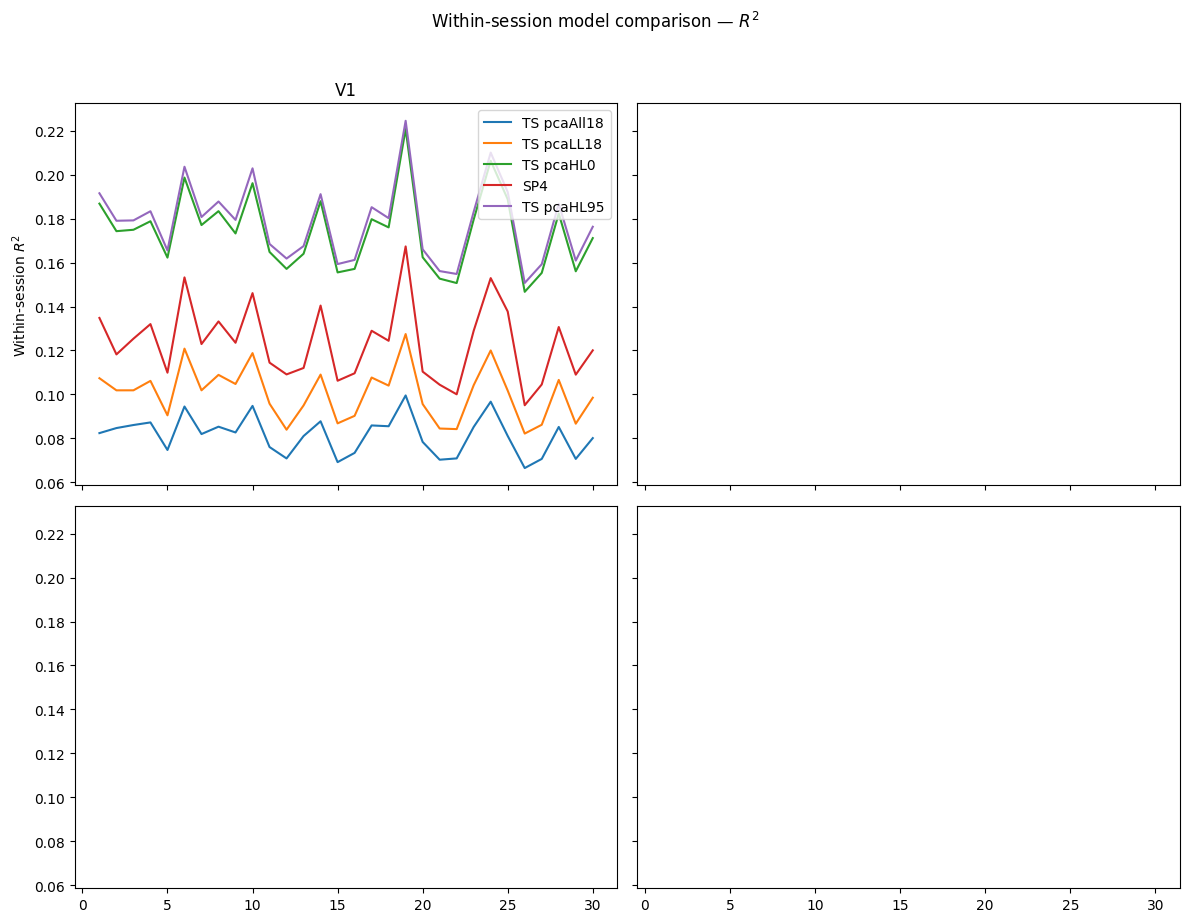

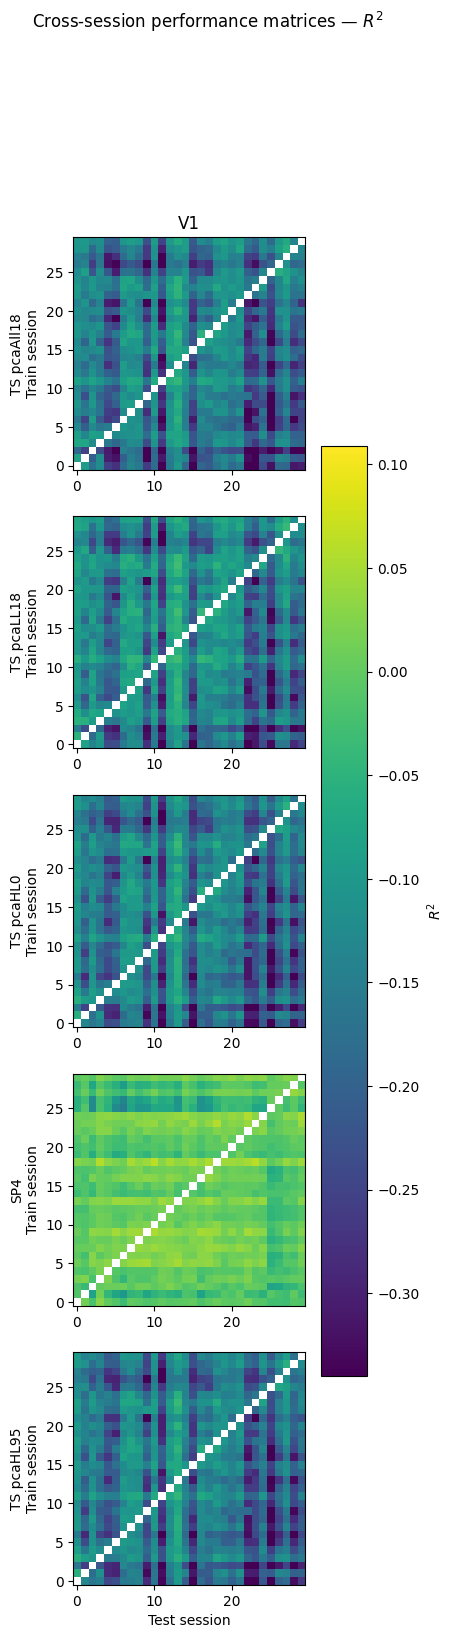

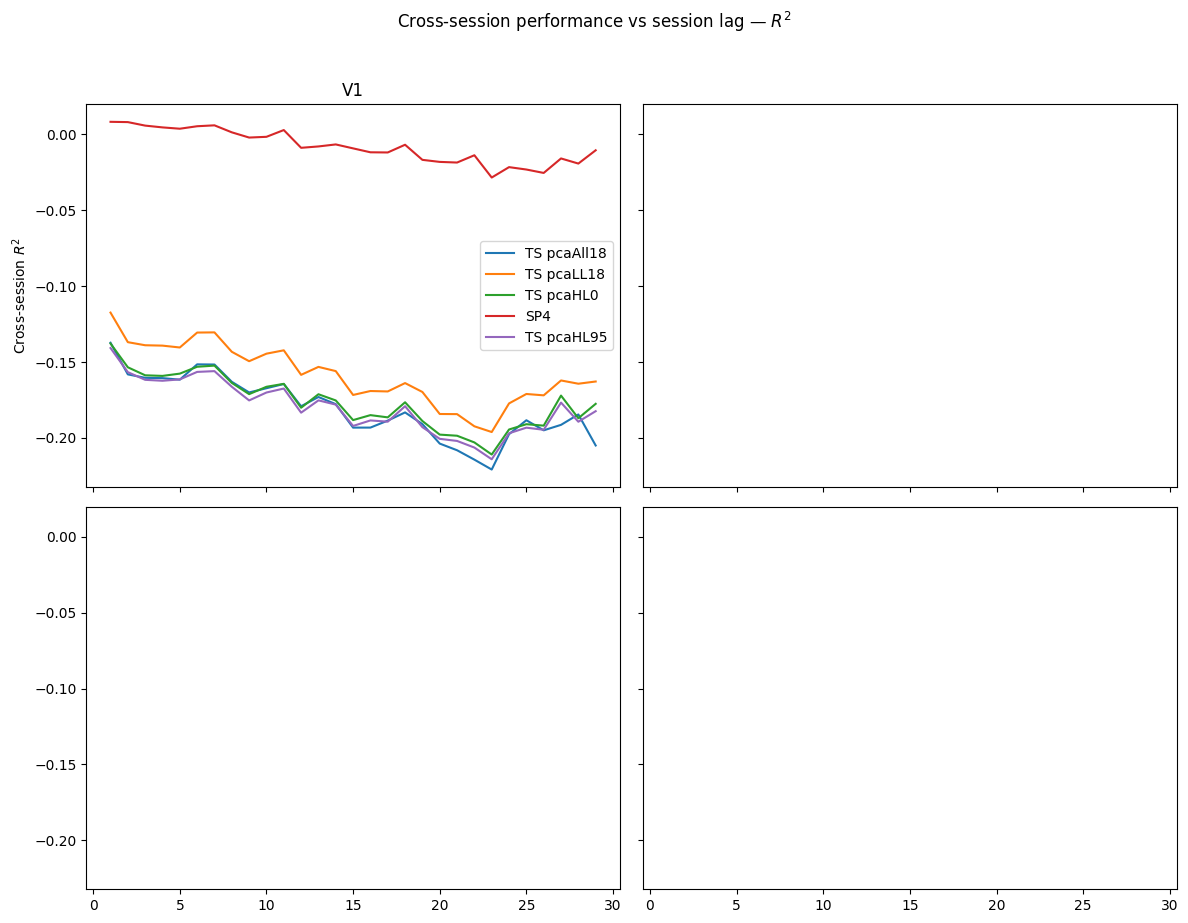

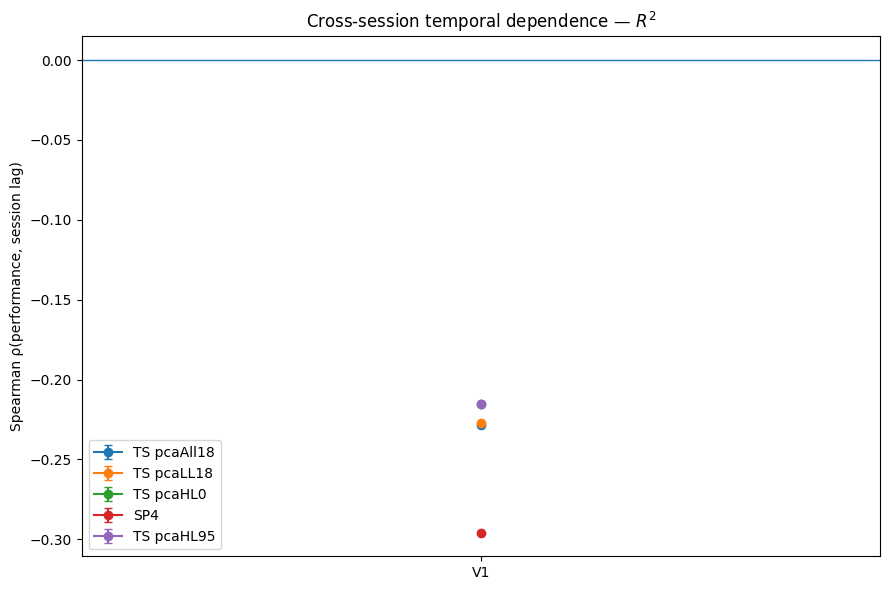

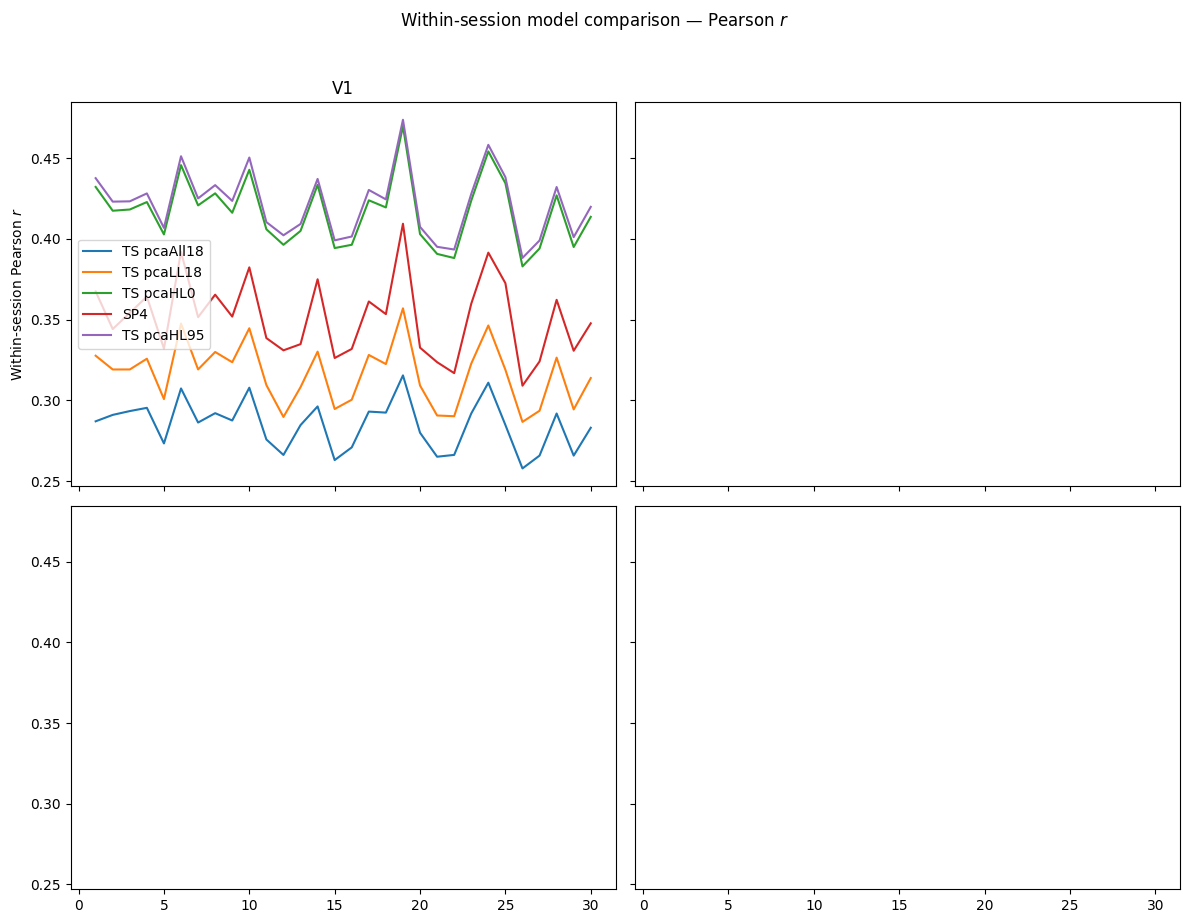

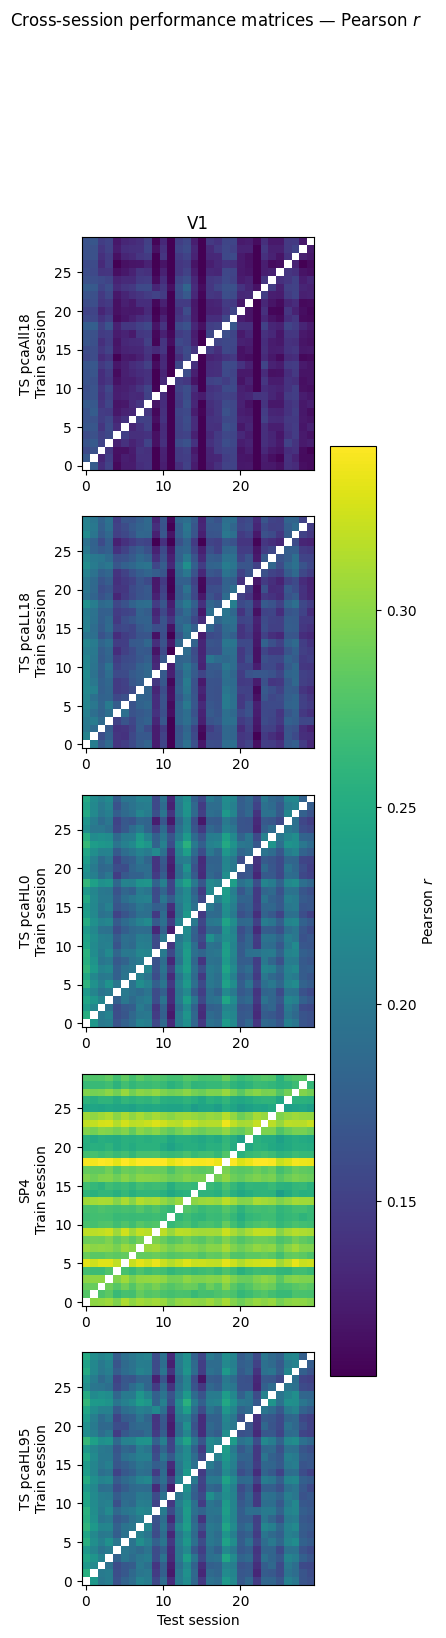

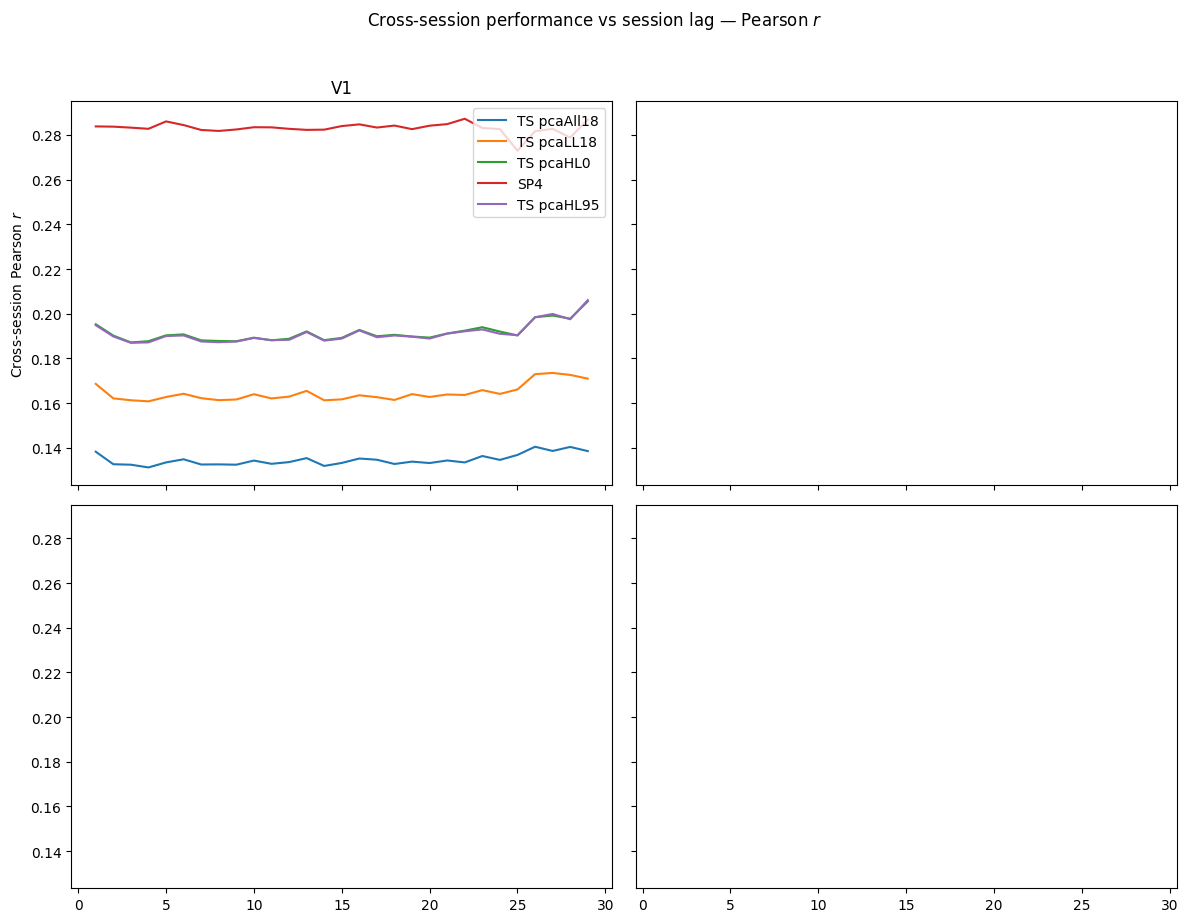

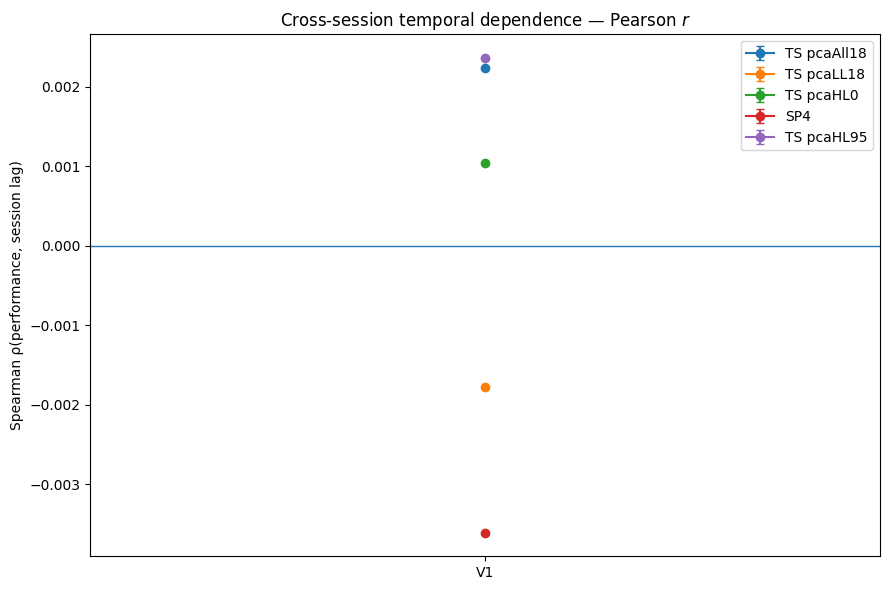

In [42]:
# =============================================================================
# AUTOMATIC MAIN FIGURES
# =============================================================================

for metric in METRICS_TO_RUN:

    if "within" in SCOPES_TO_RUN:
        plot_within_session(
            models=ACTIVE_MODELS,
            metric=metric,
        )

    if "cross" in SCOPES_TO_RUN:
        plot_cross_heatmaps(
            models=ACTIVE_MODELS,
            metric=metric,
            mask_diagonal=True,
        )

        plot_cross_lag_curves(
            models=ACTIVE_MODELS,
            metric=metric,
        )

        plot_drift_by_roi(
            models=ACTIVE_MODELS,
            metric=metric,
        )


## 7. pRF R² versus model performance — generic

For each model, metric, and scope:

- **within:** each voxel contributes its pRF R² and its mean within-session performance across 30 sessions.
- **cross:** each voxel contributes its pRF R² and its mean off-diagonal cross-session performance.

The pooled voxel Spearman correlation is descriptive; subject-level correlations are also calculated below.

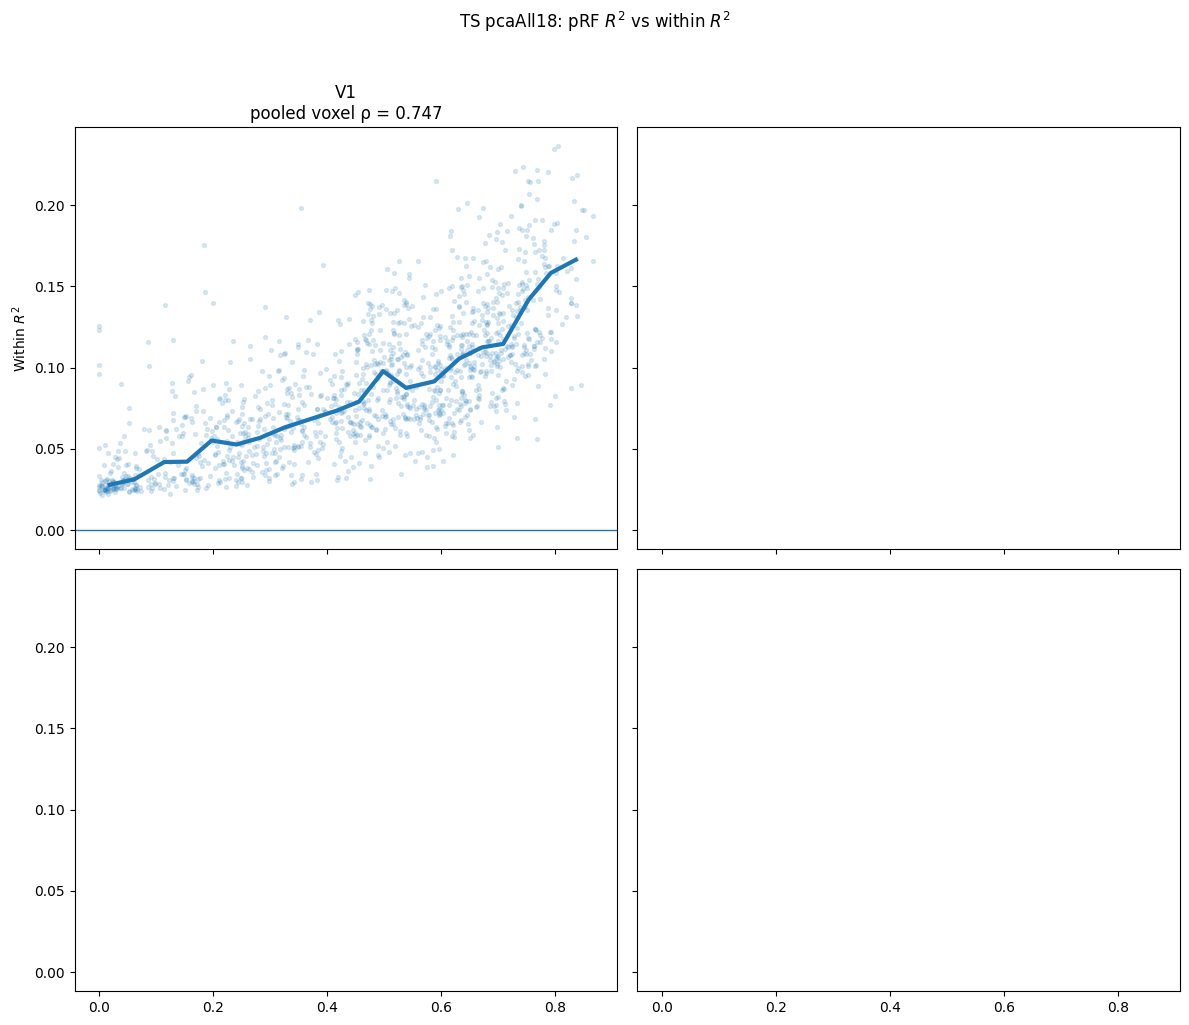

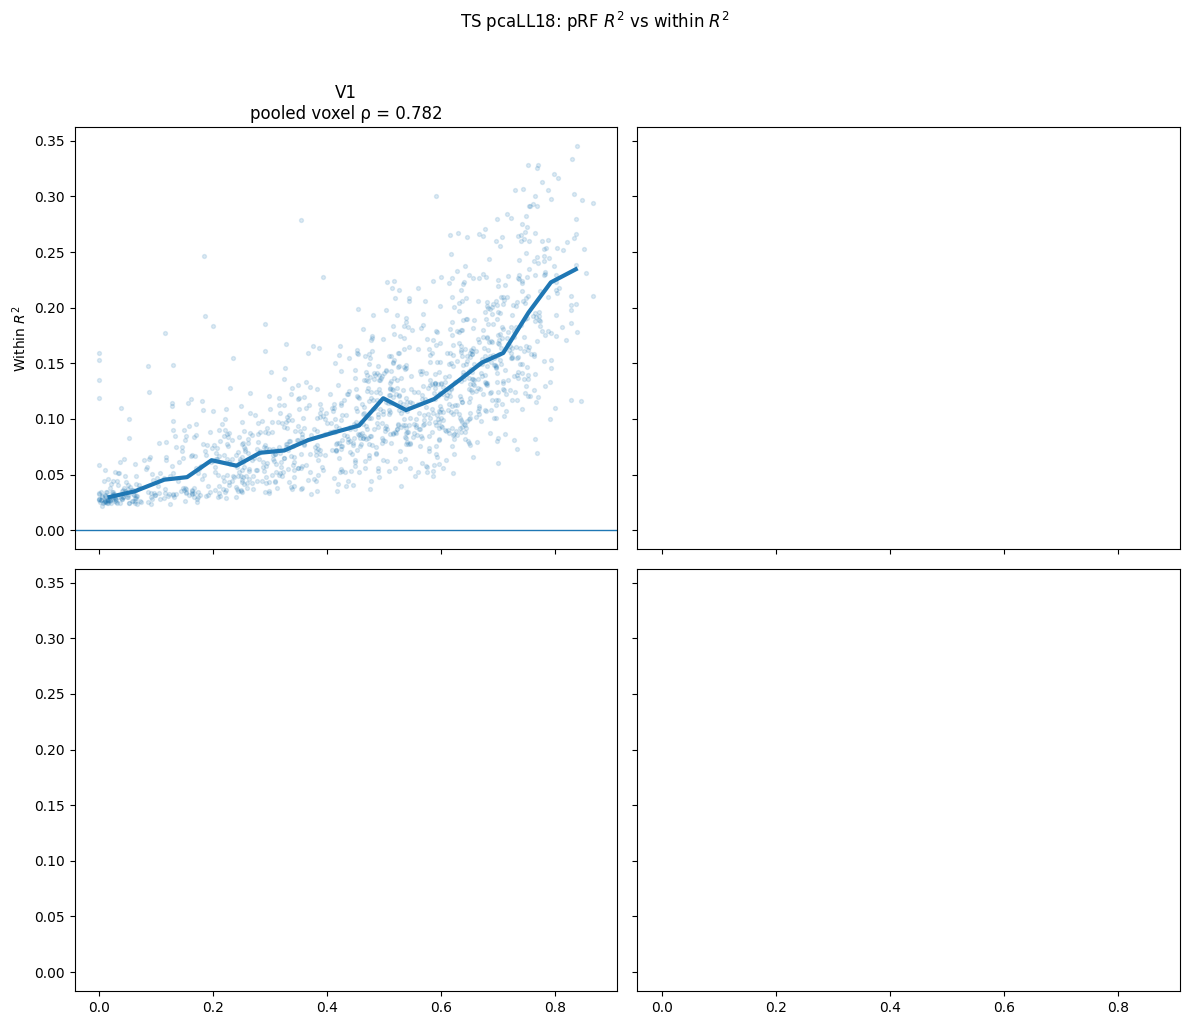

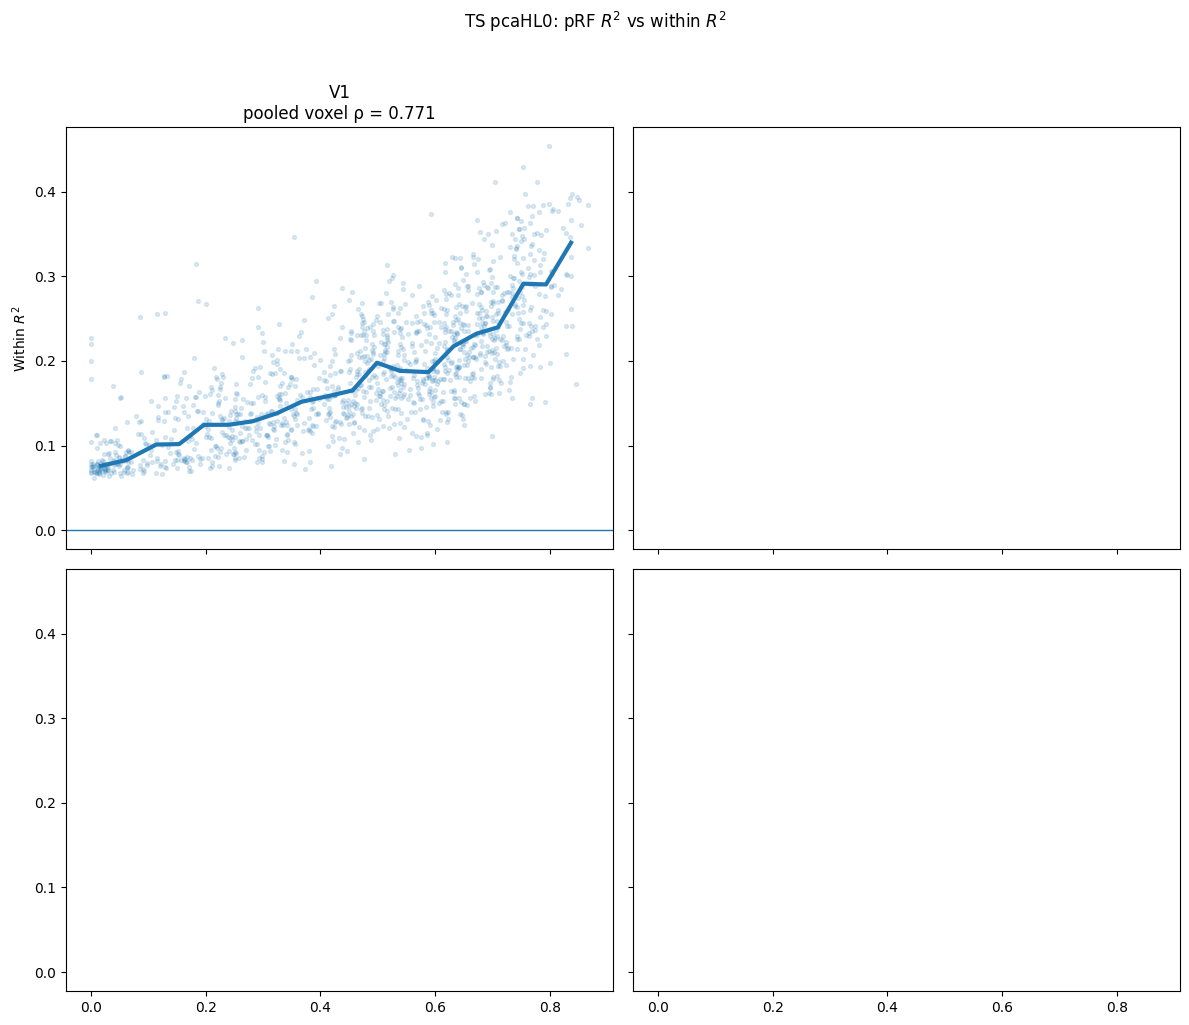

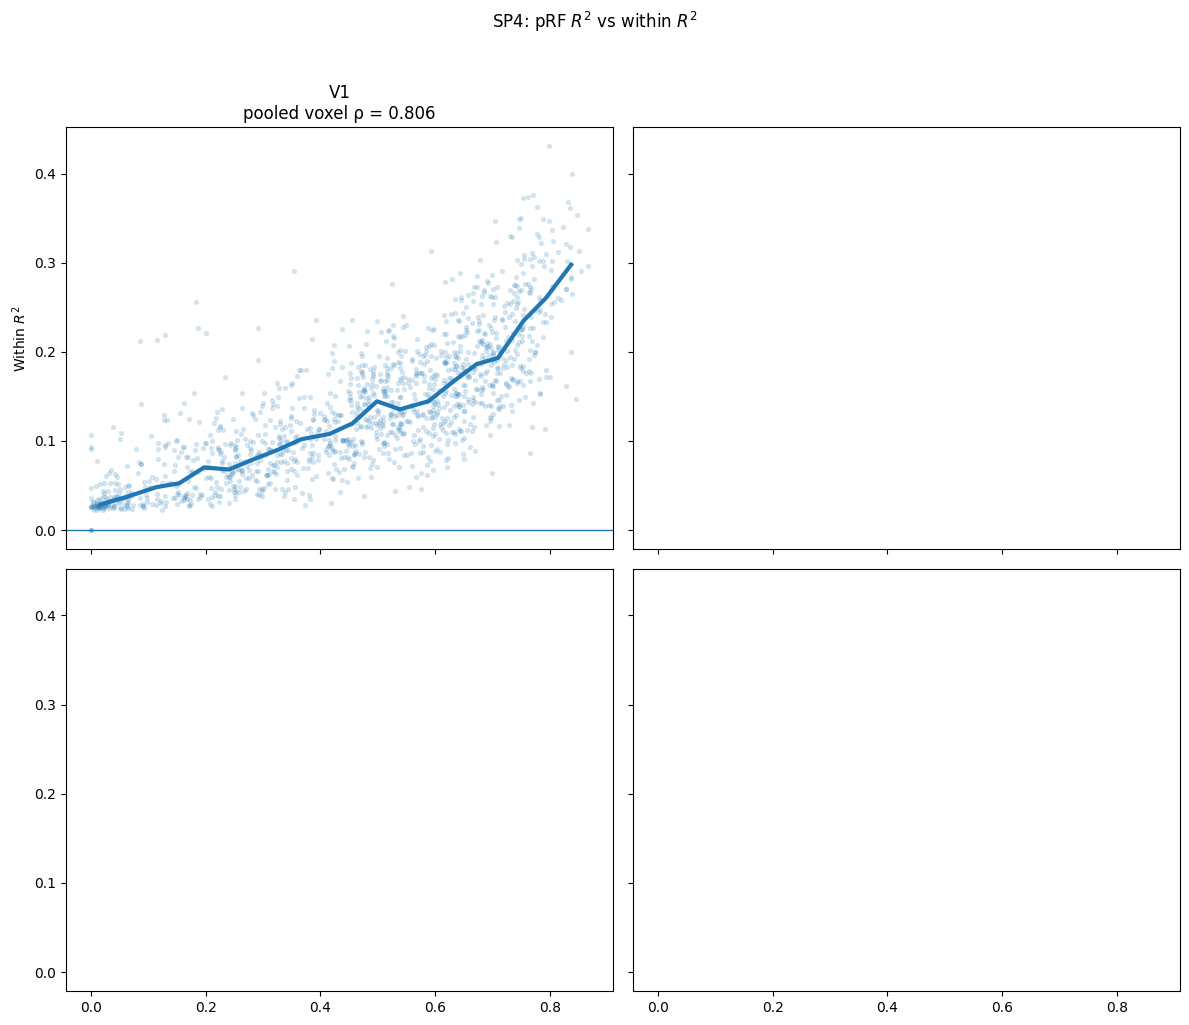

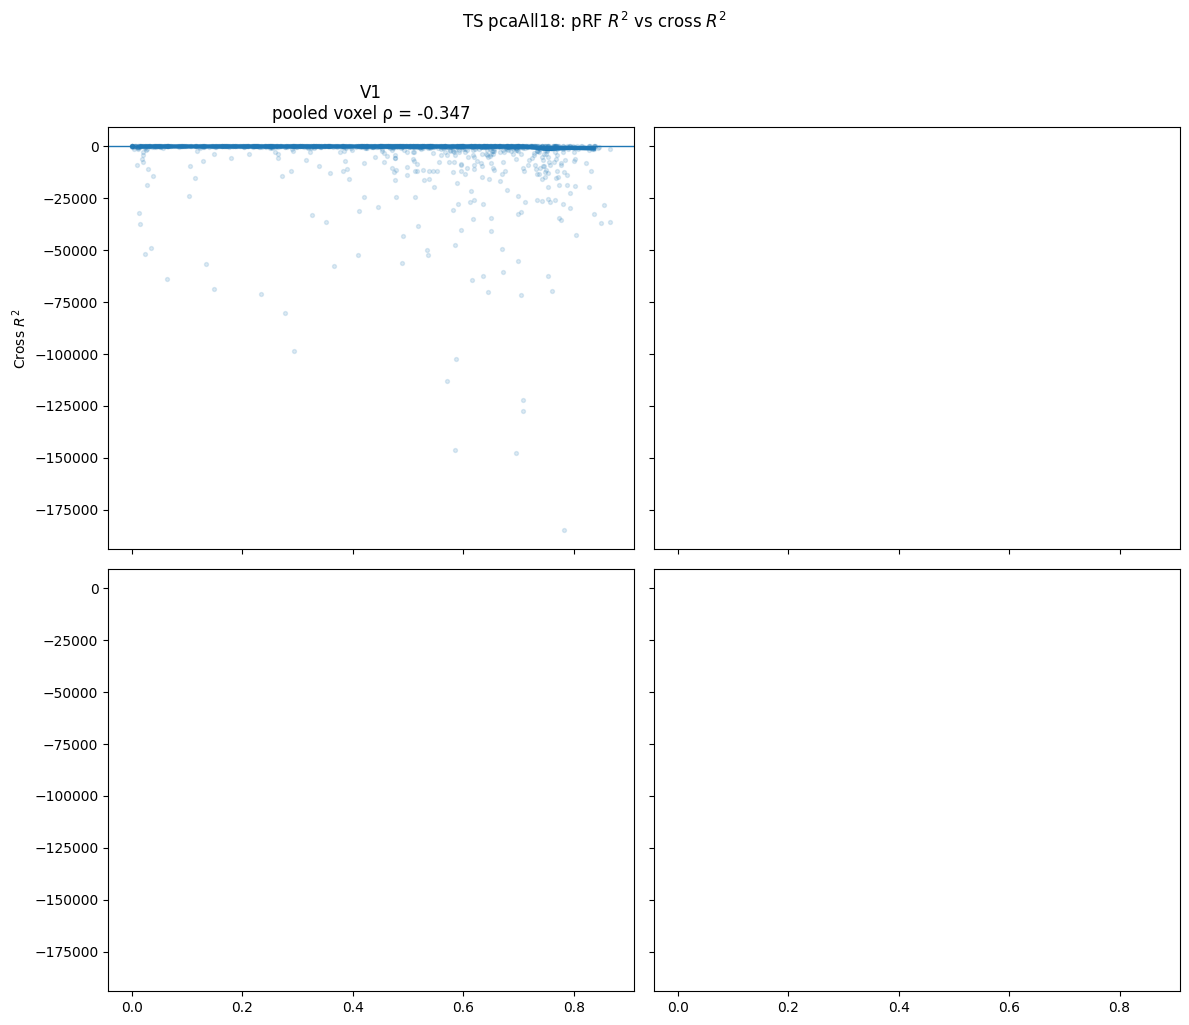

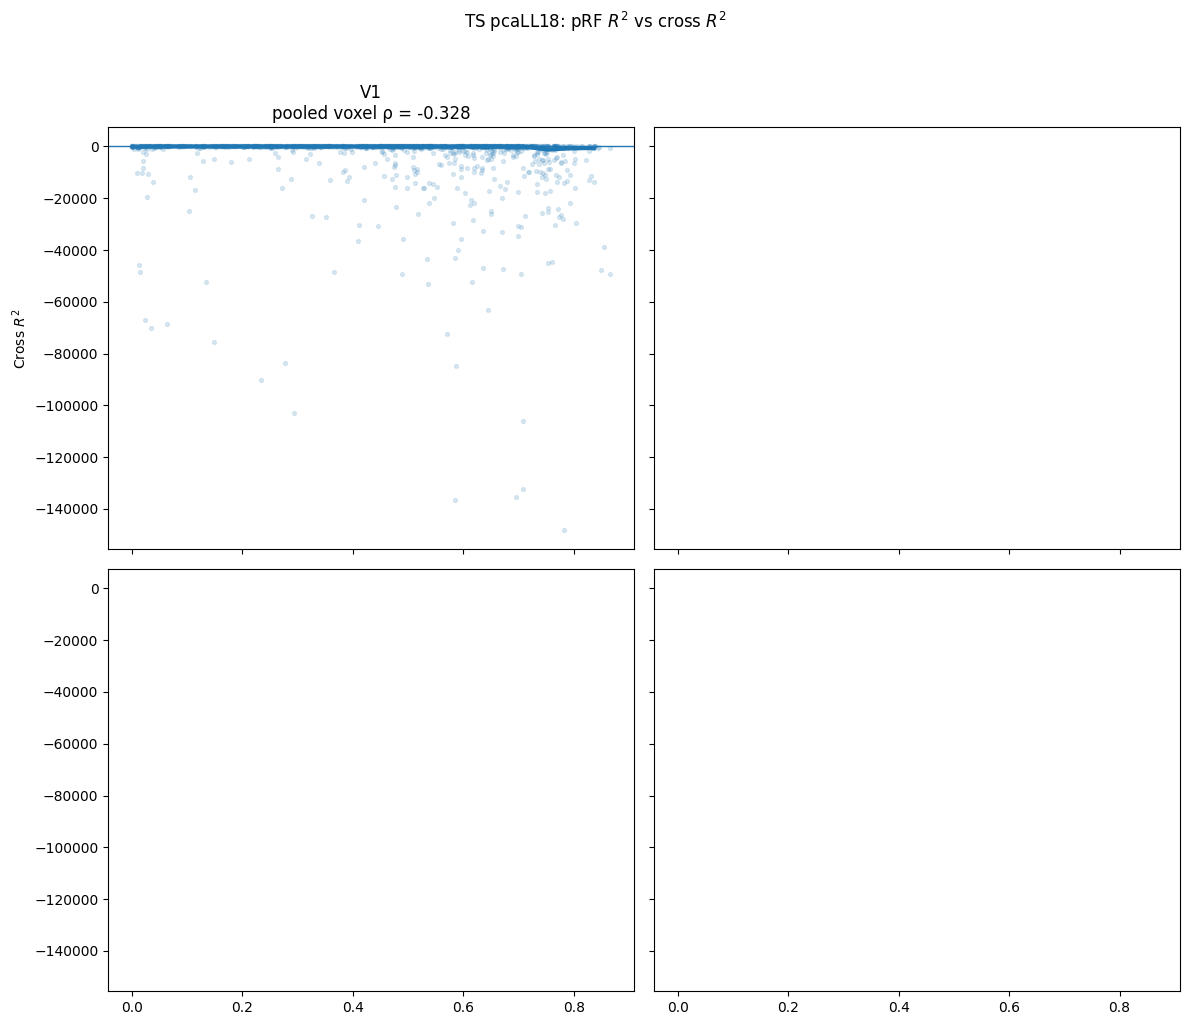

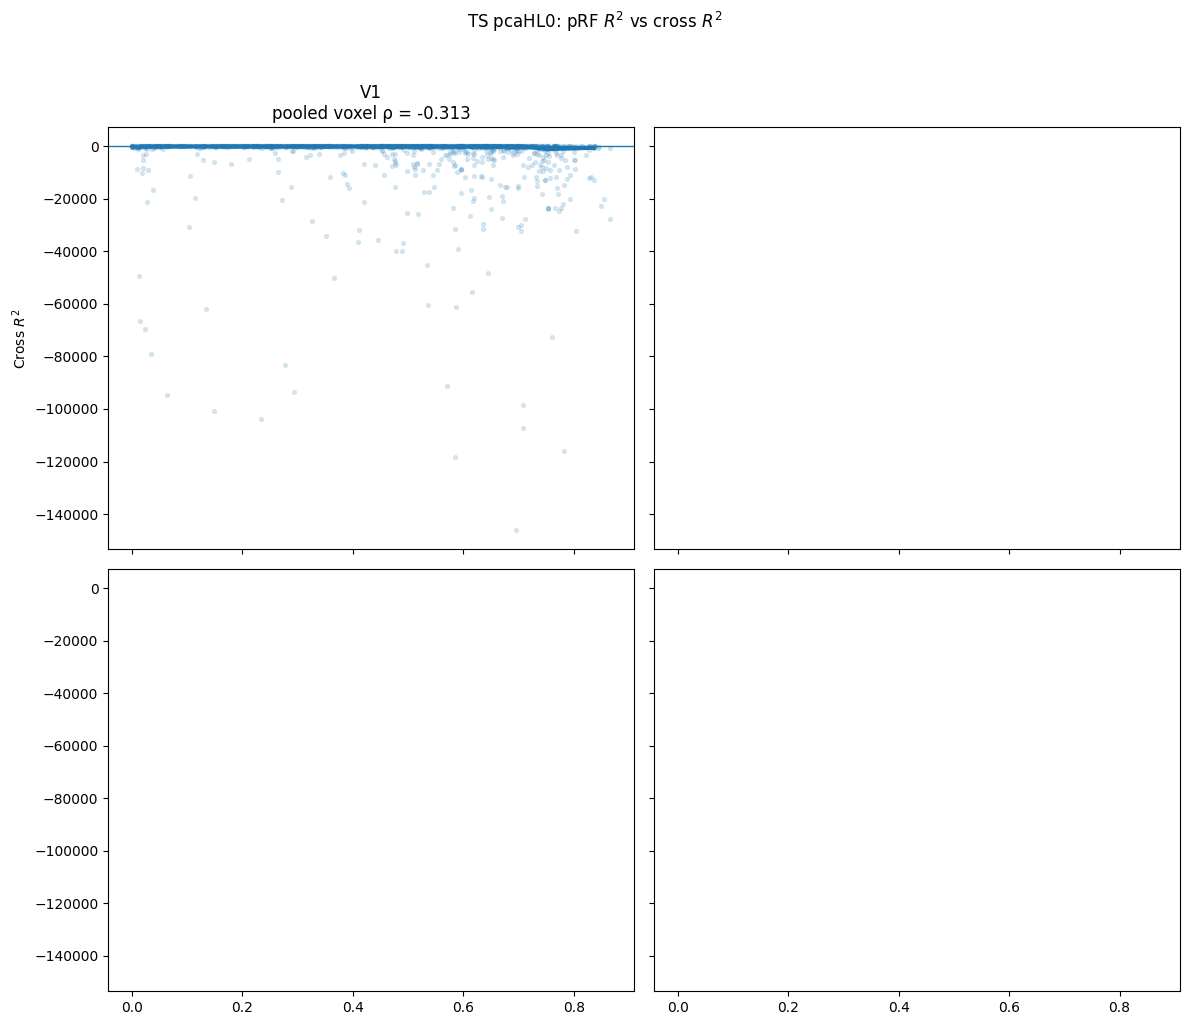

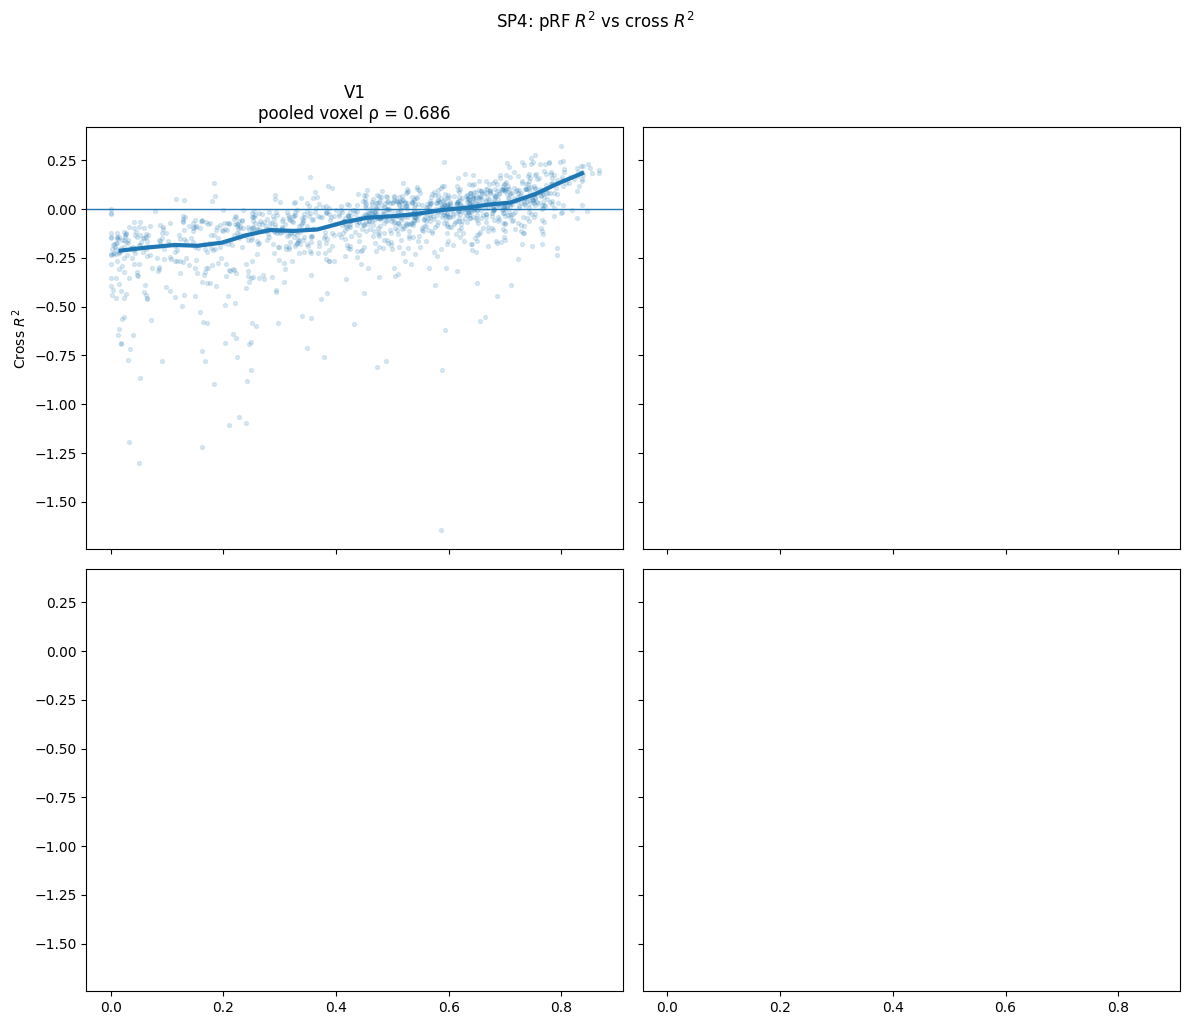

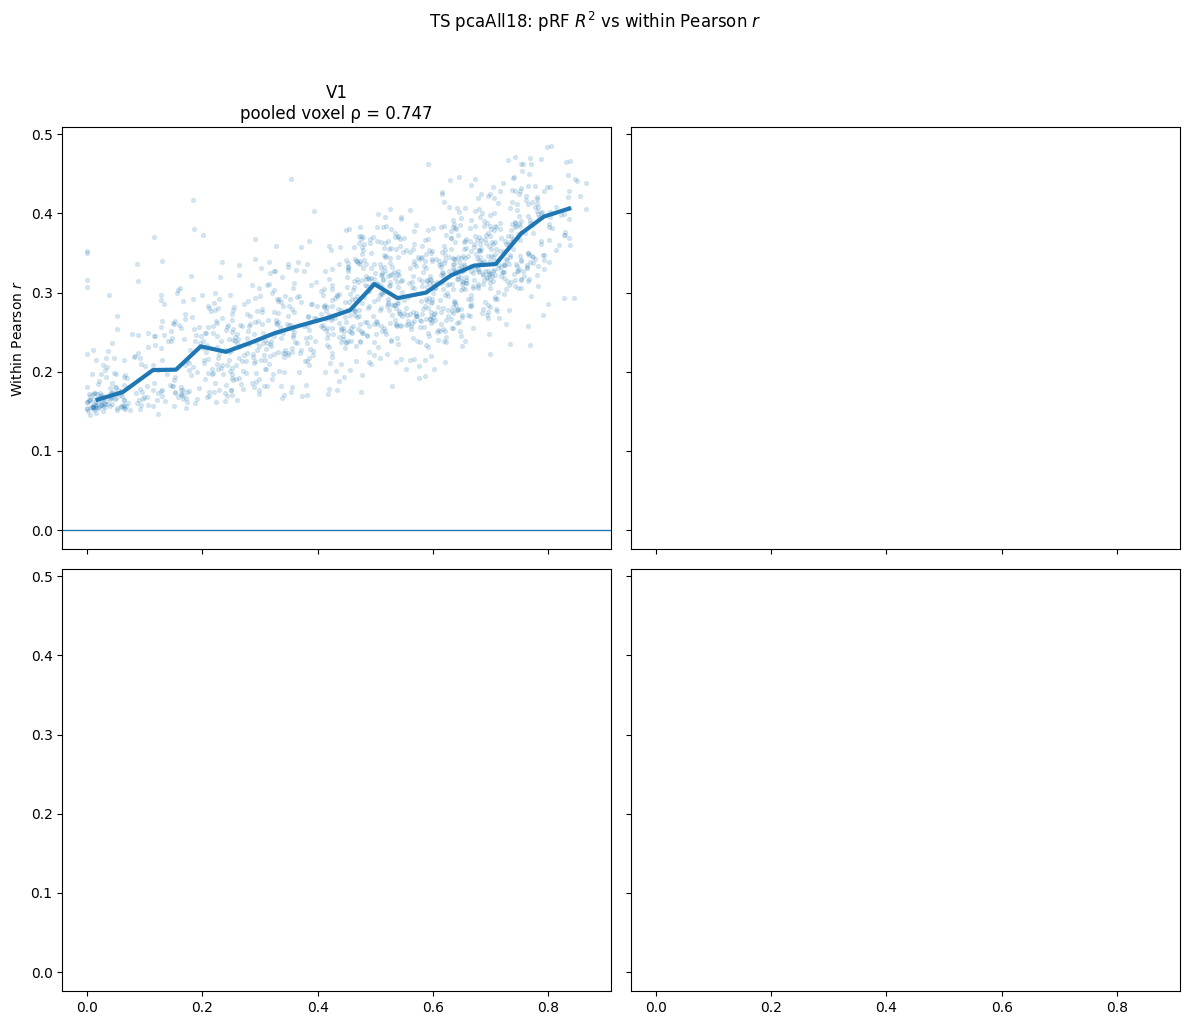

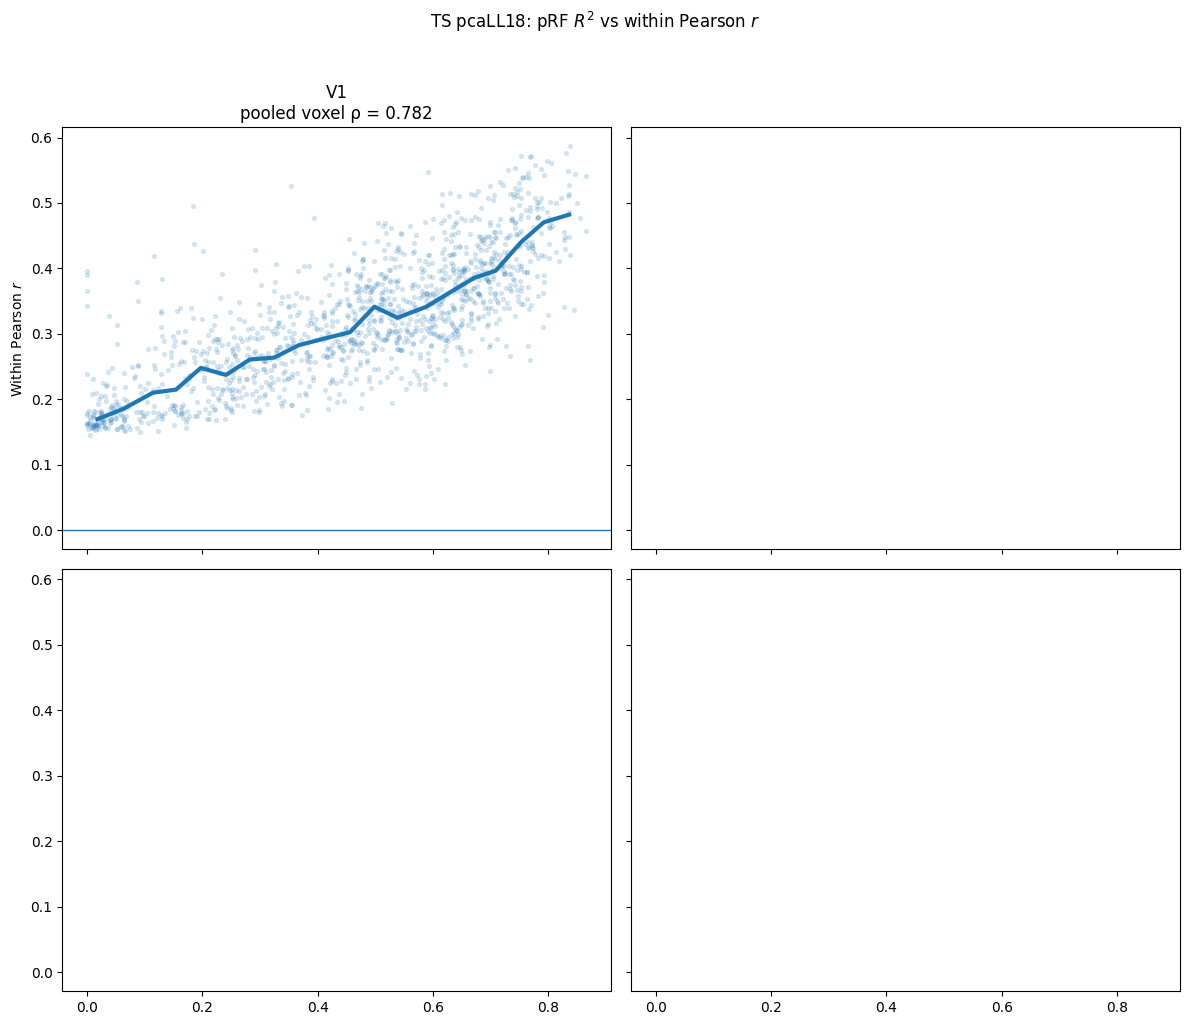

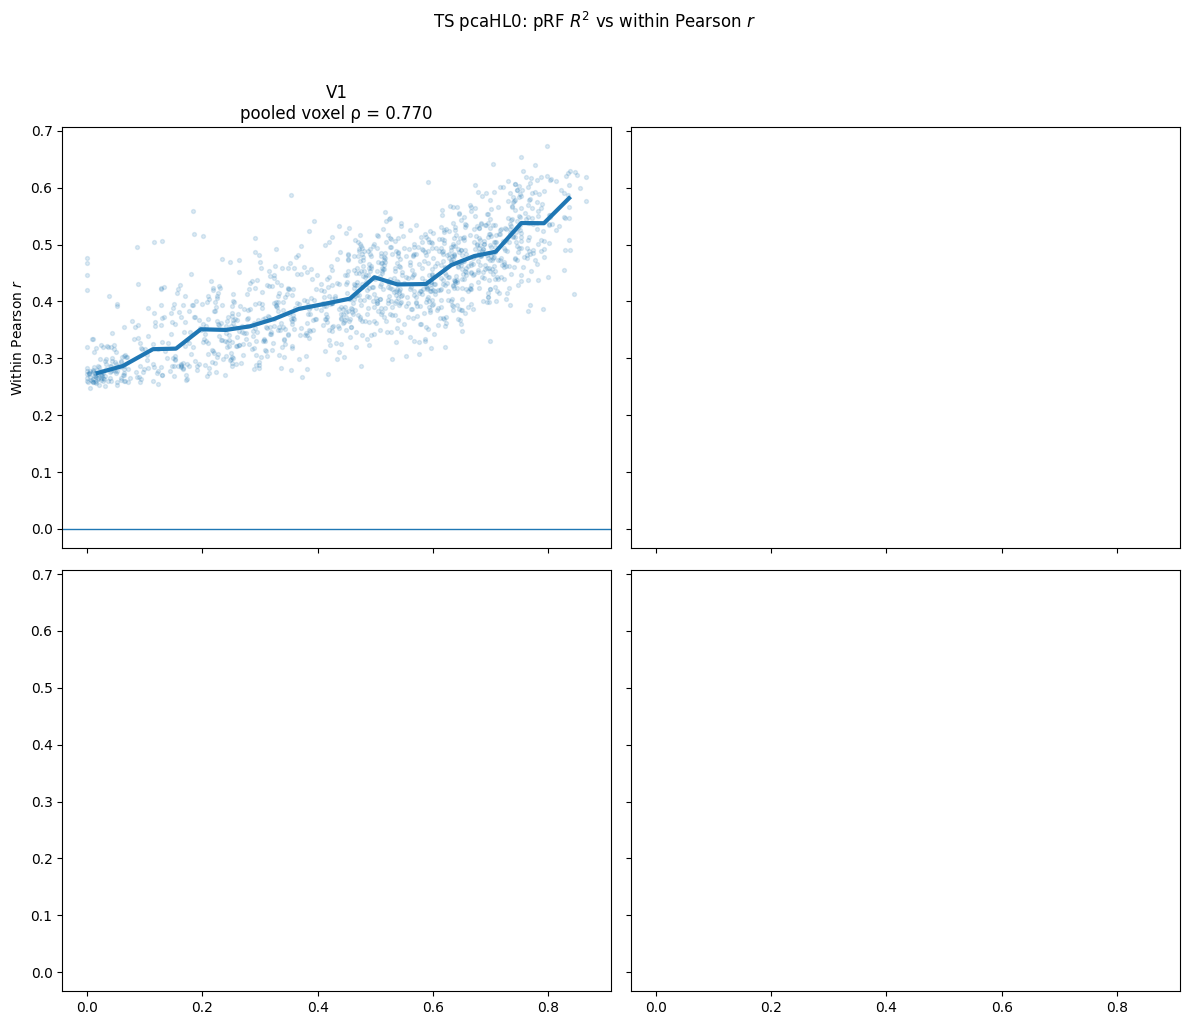

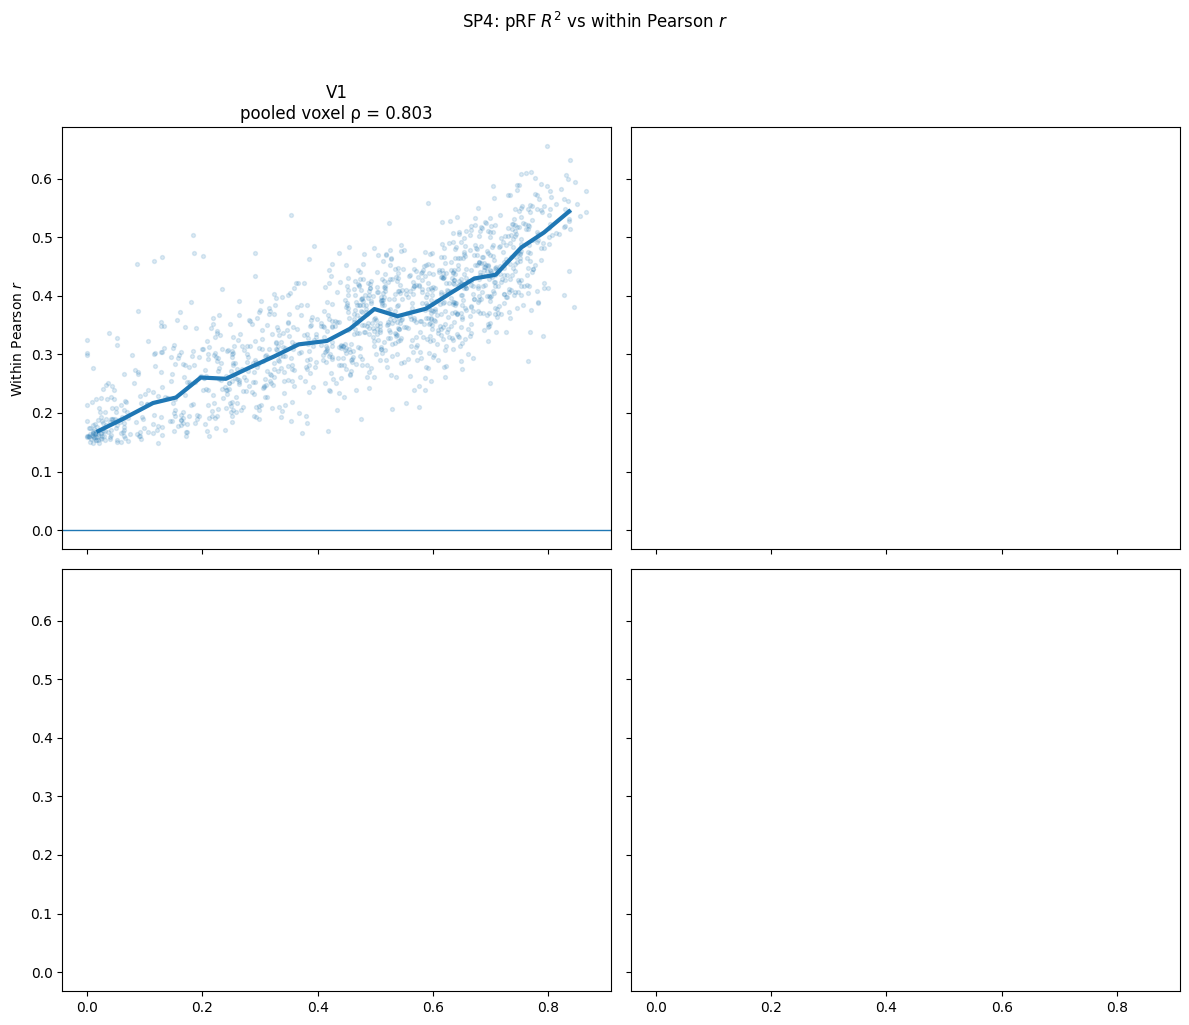

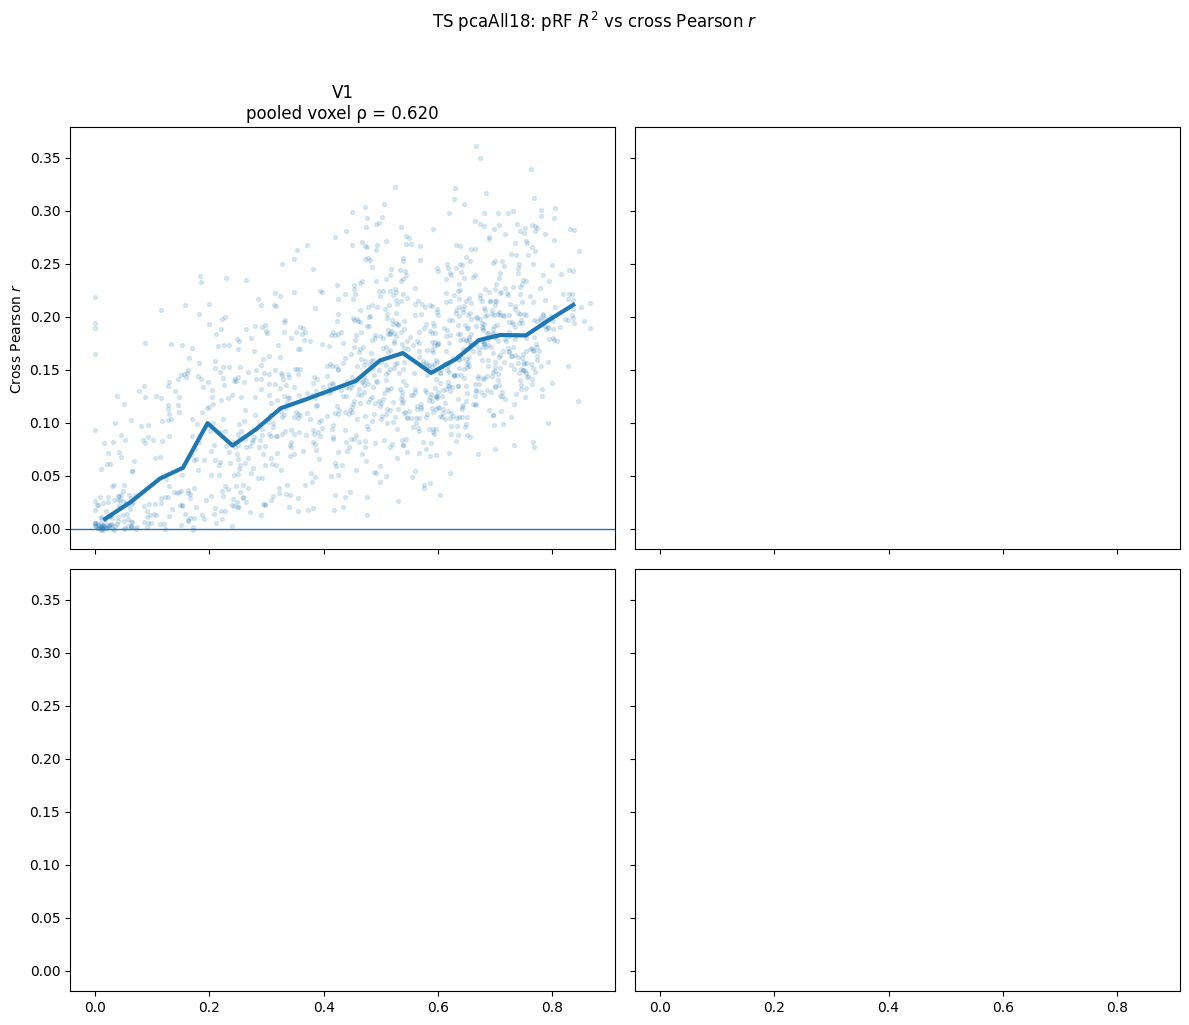

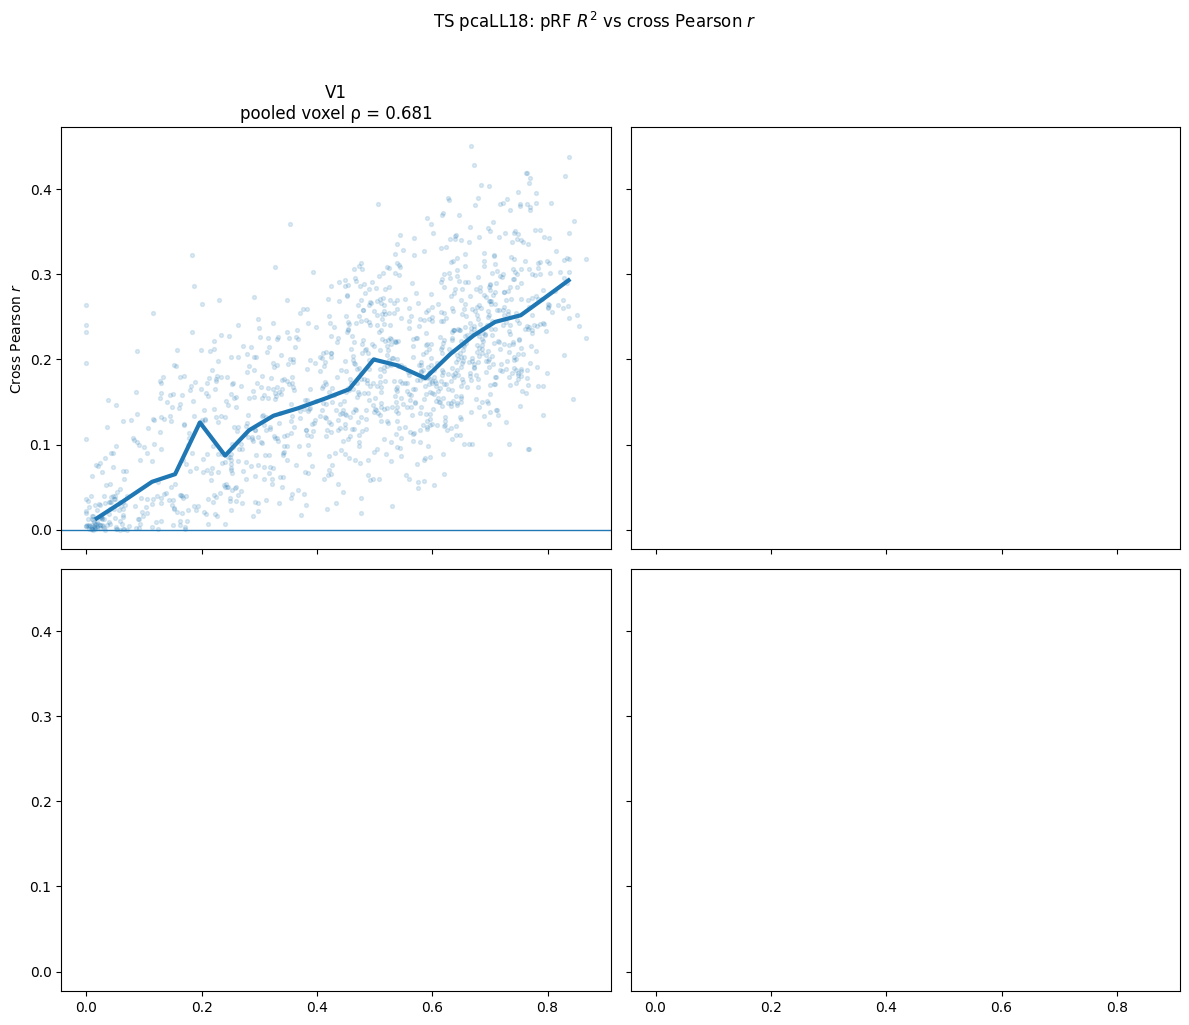

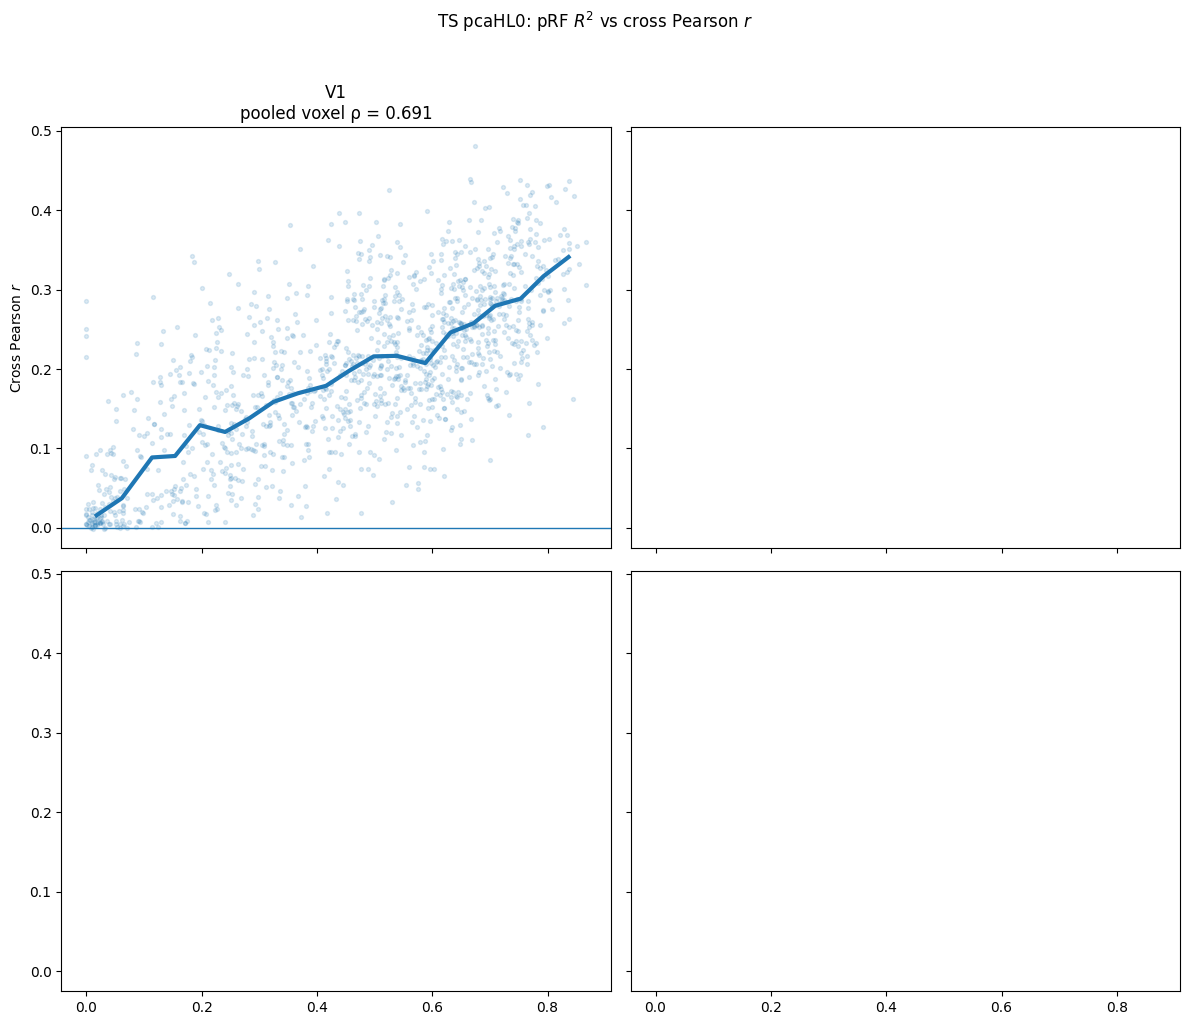

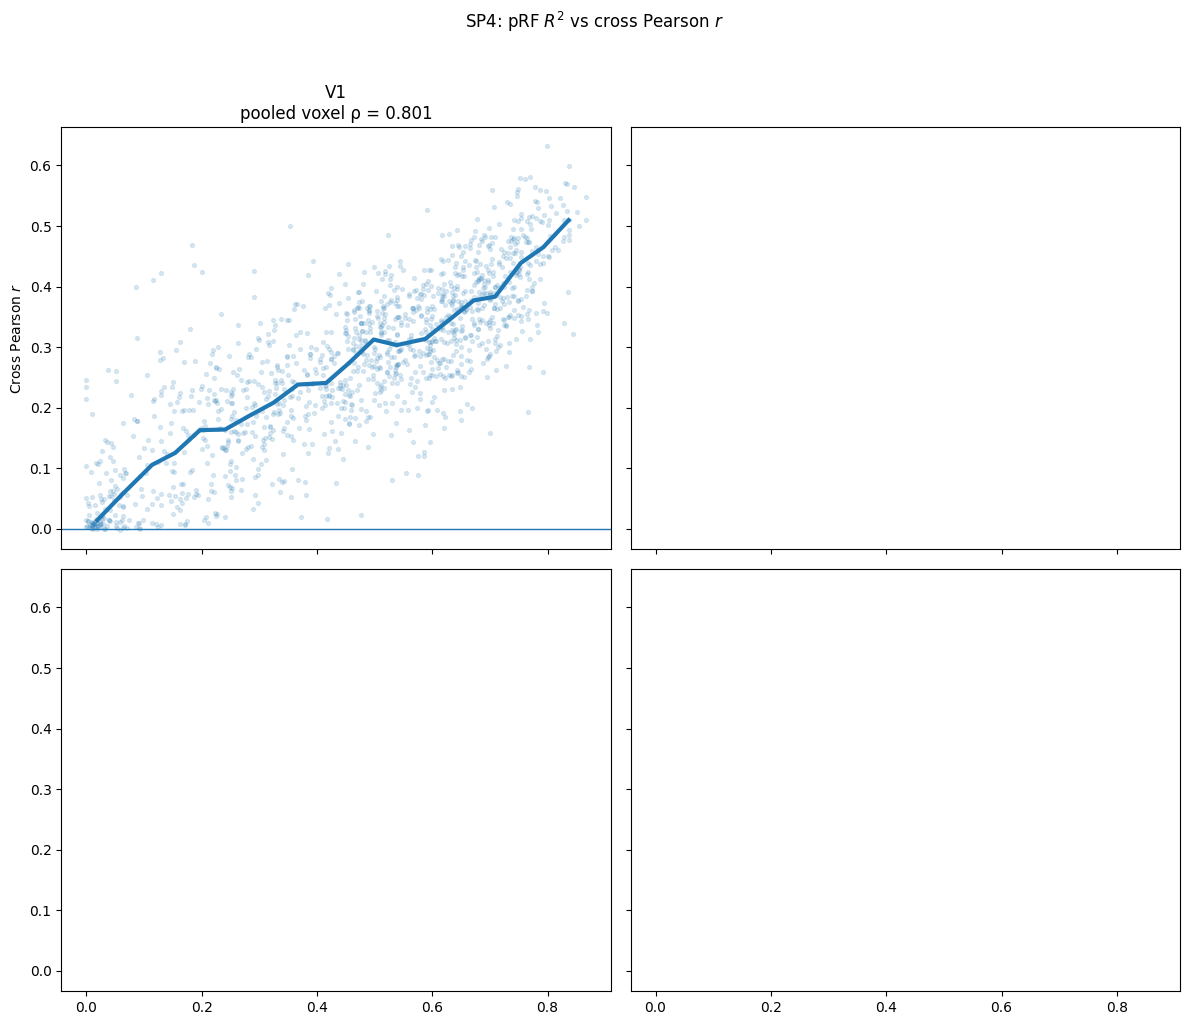

In [ ]:
# =============================================================================
# pRF R² vs ABSOLUTE MODEL PERFORMANCE
# =============================================================================

def plot_prf_vs_performance(models, metric, scope):
    perf_col = (
        "within_performance"
        if scope == "within"
        else "cross_performance"
    )

    for model in models:
        d_model = voxel_df[
            (voxel_df["model"] == model)
            & (voxel_df["metric"] == metric)
        ]

        if d_model.empty or not np.isfinite(d_model["prf_r2"]).any():
            continue

        fig, axes = plt.subplots(
            2, 2,
            figsize=(12, 10),
            sharex=True,
            sharey=True,
        )
        axes = axes.ravel()

        for i, (ax, roi) in enumerate(zip(axes, ROIS)):
            d = d_model[d_model["roi"] == roi]

            valid = (
                np.isfinite(d["prf_r2"])
                & np.isfinite(d[perf_col])
            )

            x = d.loc[valid, "prf_r2"].to_numpy()
            y = d.loc[valid, perf_col].to_numpy()

            if len(x) >= 3:
                rho, _ = spearmanr(x, y)
            else:
                rho = np.nan

            ax.scatter(x, y, s=8, alpha=0.15)
            add_binned_median_line(ax, x, y)
            ax.axhline(0, linewidth=1)

            ax.set_title(
                f"{roi}\npooled voxel ρ = {rho:.3f}"
            )

            if i >= 2:
                ax.set_xlabel("pRF $R^2$")

            if i % 2 == 0:
                ax.set_ylabel(
                    f"{scope.capitalize()} {METRIC_LABEL[metric]}"
                )

        fig.suptitle(
            f"{MODEL_SPECS[model]['label']}: pRF $R^2$ vs "
            f"{scope} {METRIC_LABEL[metric]}",
            y=1.02,
        )
        plt.tight_layout()
        plt.show()


for metric in METRICS_TO_RUN:
    for scope in SCOPES_TO_RUN:
        plot_prf_vs_performance(
            models=ACTIVE_MODELS,
            metric=metric,
            scope=scope,
        )


## 8. Subject-level pRF correlations

This table is the safer inferential summary than pooling all voxels across subjects.

In [ ]:
# =============================================================================
# SUBJECT-LEVEL pRF CORRELATIONS
# =============================================================================

prf_corr_rows = []

for model in ACTIVE_MODELS:
    for subject in SUBJECTS:
        for roi in ROIS:
            for metric in METRICS_TO_RUN:
                d = voxel_df[
                    (voxel_df["model"] == model)
                    & (voxel_df["subject"] == subject)
                    & (voxel_df["roi"] == roi)
                    & (voxel_df["metric"] == metric)
                ]

                for scope, perf_col in [
                    ("within", "within_performance"),
                    ("cross", "cross_performance"),
                ]:
                    valid = (
                        np.isfinite(d["prf_r2"])
                        & np.isfinite(d[perf_col])
                    )

                    if valid.sum() >= 3:
                        rho, p = spearmanr(
                            d.loc[valid, "prf_r2"],
                            d.loc[valid, perf_col],
                        )
                    else:
                        rho, p = np.nan, np.nan

                    prf_corr_rows.append({
                        "model": model,
                        "subject": subject,
                        "roi": roi,
                        "metric": metric,
                        "scope": scope,
                        "n_voxels": int(valid.sum()),
                        "rho_prf": rho,
                        "p_value": p,
                    })

prf_corr_df = pd.DataFrame(prf_corr_rows)

prf_corr_summary = (
    prf_corr_df
    .groupby(["model", "roi", "metric", "scope"])["rho_prf"]
    .agg(["mean", "std", "median", "count"])
    .reset_index()
)

display(prf_corr_summary)


,model,roi,metric,scope,mean,std,median,count
0,SP4,V1,pearson,cross,0.801235,NaN,0.801235,1
1,SP4,V1,pearson,within,0.803470,NaN,0.803470,1
2,SP4,V1,r2,cross,0.686412,NaN,0.686412,1
3,SP4,V1,r2,within,0.805828,NaN,0.805828,1
4,TS_pcaAll18,V1,pearson,cross,0.620025,NaN,0.620025,1
5,TS_pcaAll18,V1,pearson,within,0.746998,NaN,0.746998,1
6,TS_pcaAll18,V1,r2,cross,-0.347270,NaN,-0.347270,1
7,TS_pcaAll18,V1,r2,within,0.747460,NaN,0.747460,1
8,TS_pcaHL0,V1,pearson,cross,0.690704,NaN,0.690704,1
9,TS_pcaHL0,V1,pearson,within,0.770492,NaN,0.770492,1


## 9. Generic pairwise comparison, including pRF R² versus model difference

Use this function for **any pair** of models. You do not need a separate cell for SP4-vs-SP6, TS-vs-SP4, pcaHL0-vs-pcaHL95, etc.

The function aligns voxels by `voxel_index`, then computes:

**difference = model_B − model_A**

for either R² or Pearson and for either within- or cross-session performance.

In [ ]:
# =============================================================================
# GENERIC PAIRWISE VOXEL COMPARISON
# =============================================================================

def build_pairwise_voxel_df(model_a, model_b, metric, scope):
    perf_col = (
        "within_performance"
        if scope == "within"
        else "cross_performance"
    )

    a = voxel_df[
        (voxel_df["model"] == model_a)
        & (voxel_df["metric"] == metric)
    ].copy()

    b = voxel_df[
        (voxel_df["model"] == model_b)
        & (voxel_df["metric"] == metric)
    ].copy()

    # Require grounded global voxel indices for exact alignment.
    a = a[np.isfinite(a["voxel_index"])].copy()
    b = b[np.isfinite(b["voxel_index"])].copy()

    keys = ["subject", "roi", "voxel_index"]

    a = a[
        keys + ["prf_r2", perf_col]
    ].rename(columns={
        "prf_r2": "prf_r2_a",
        perf_col: "performance_a",
    })

    b = b[
        keys + ["prf_r2", perf_col]
    ].rename(columns={
        "prf_r2": "prf_r2_b",
        perf_col: "performance_b",
    })

    out = a.merge(
        b,
        on=keys,
        how="inner",
        validate="one_to_one",
    )

    out["prf_r2"] = out["prf_r2_b"].where(
        np.isfinite(out["prf_r2_b"]),
        out["prf_r2_a"],
    )

    out["difference_B_minus_A"] = (
        out["performance_b"] - out["performance_a"]
    )

    out["model_a"] = model_a
    out["model_b"] = model_b
    out["metric"] = metric
    out["scope"] = scope

    return out


def plot_prf_vs_model_difference(
    model_a,
    model_b,
    metric,
    scope,
):
    d_all = build_pairwise_voxel_df(
        model_a=model_a,
        model_b=model_b,
        metric=metric,
        scope=scope,
    )

    if d_all.empty:
        print(
            f"No aligned voxels for {model_b} - {model_a}, "
            f"{metric}, {scope}."
        )
        return d_all

    fig, axes = plt.subplots(
        2, 2,
        figsize=(12, 10),
        sharex=True,
        sharey=True,
    )
    axes = axes.ravel()

    for i, (ax, roi) in enumerate(zip(axes, ROIS)):
        d = d_all[d_all["roi"] == roi]

        valid = (
            np.isfinite(d["prf_r2"])
            & np.isfinite(d["difference_B_minus_A"])
        )

        x = d.loc[valid, "prf_r2"].to_numpy()
        y = d.loc[valid, "difference_B_minus_A"].to_numpy()

        if len(x) >= 3:
            rho, _ = spearmanr(x, y)
        else:
            rho = np.nan

        ax.scatter(x, y, s=8, alpha=0.15)
        add_binned_median_line(ax, x, y)
        ax.axhline(0, linewidth=1)

        ax.set_title(
            f"{roi}\npooled voxel ρ = {rho:.3f}"
        )

        if i >= 2:
            ax.set_xlabel("pRF $R^2$")

        if i % 2 == 0:
            ax.set_ylabel(
                f"{MODEL_SPECS[model_b]['label']} − "
                f"{MODEL_SPECS[model_a]['label']}\n"
                f"{scope} {METRIC_LABEL[metric]}"
            )

    fig.suptitle(
        f"pRF $R^2$ vs model difference: "
        f"{MODEL_SPECS[model_b]['label']} − "
        f"{MODEL_SPECS[model_a]['label']}\n"
        f"{scope} {METRIC_LABEL[metric]}",
        y=1.03,
    )
    plt.tight_layout()
    plt.show()

    return d_all


## 10. Choose comparisons once, then generate every R²/Pearson × within/cross combination

Add or remove model pairs only in `PAIRWISE_COMPARISONS`.

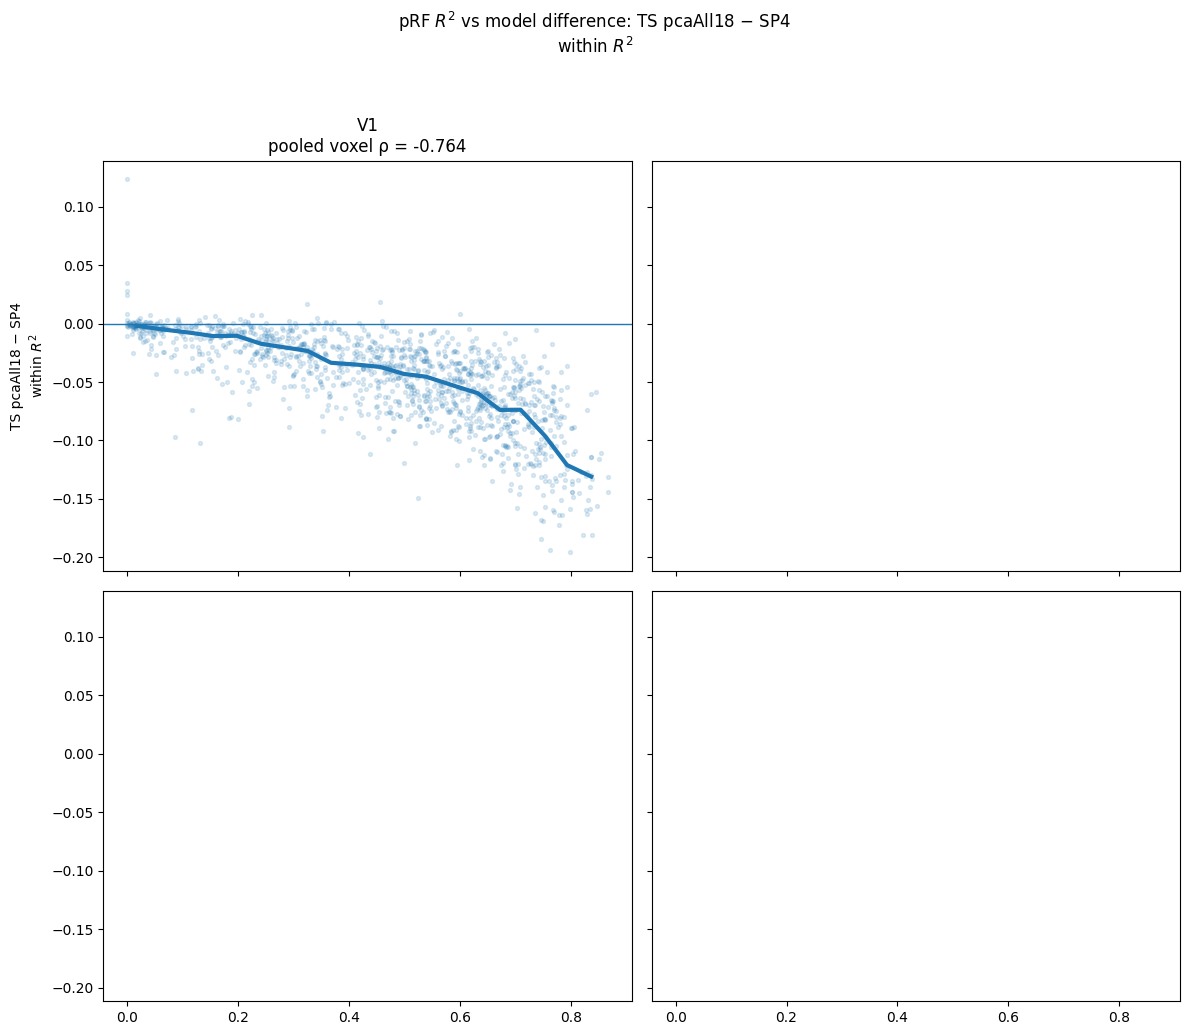

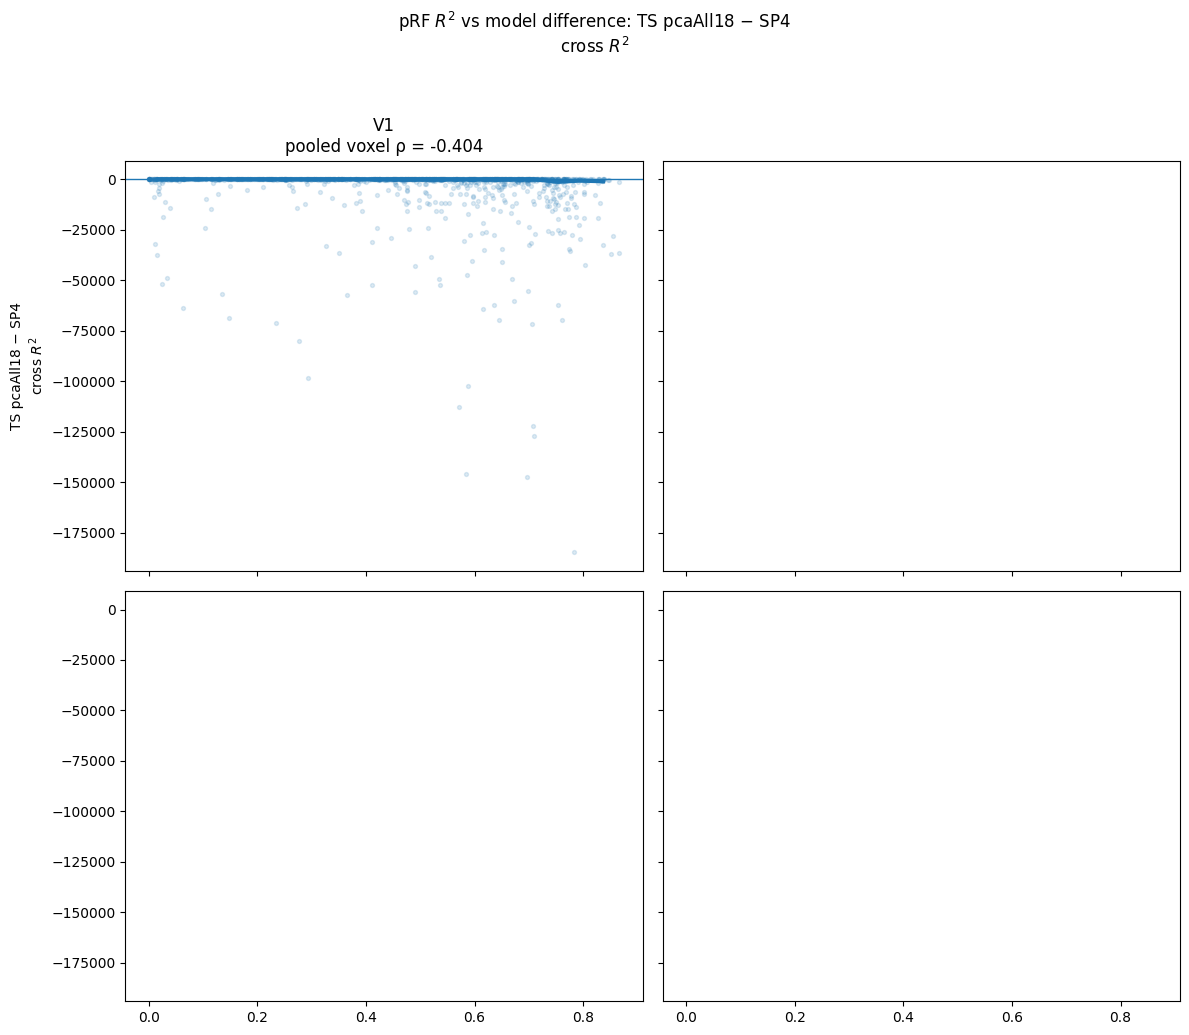

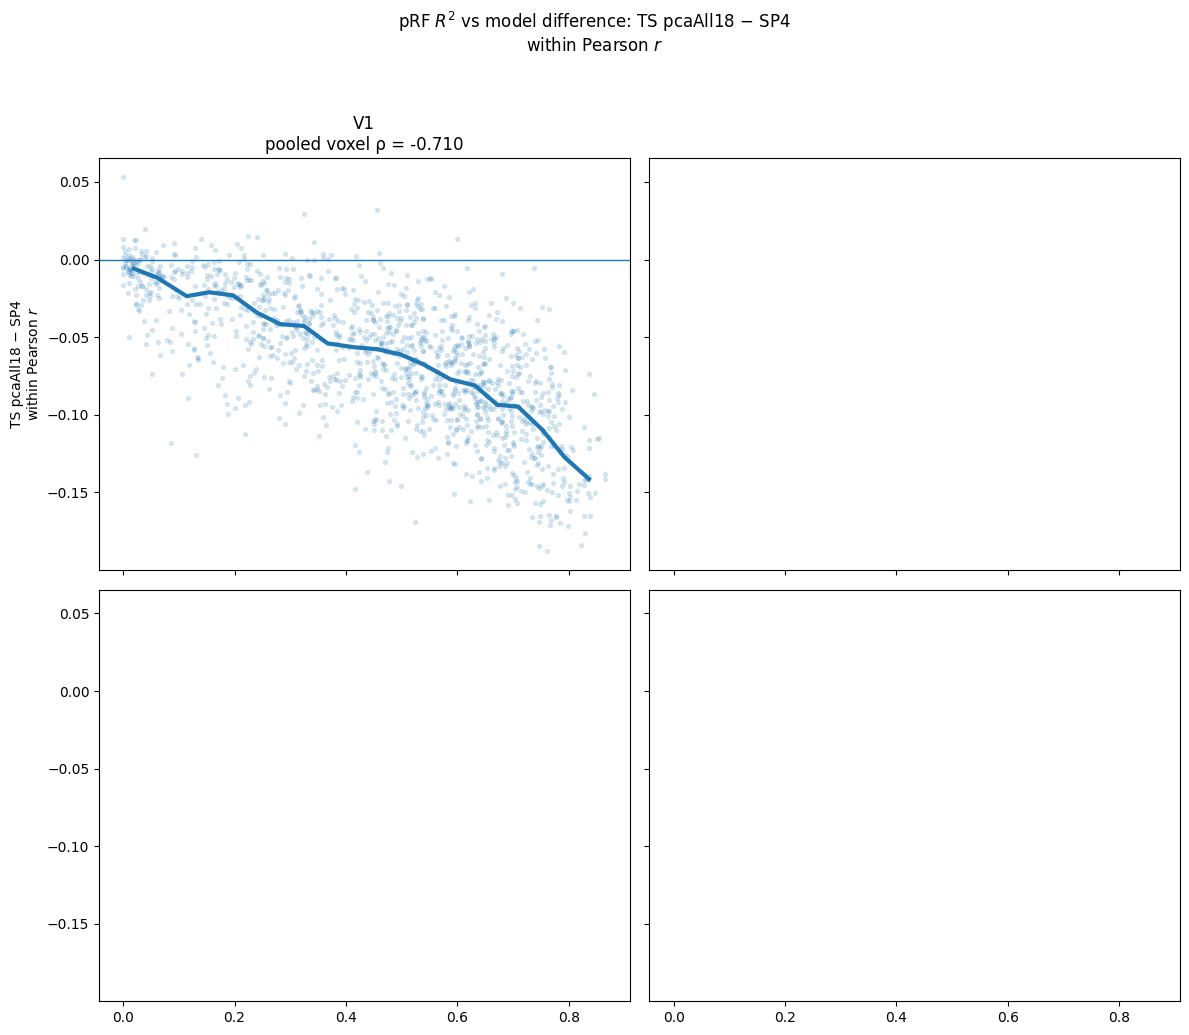

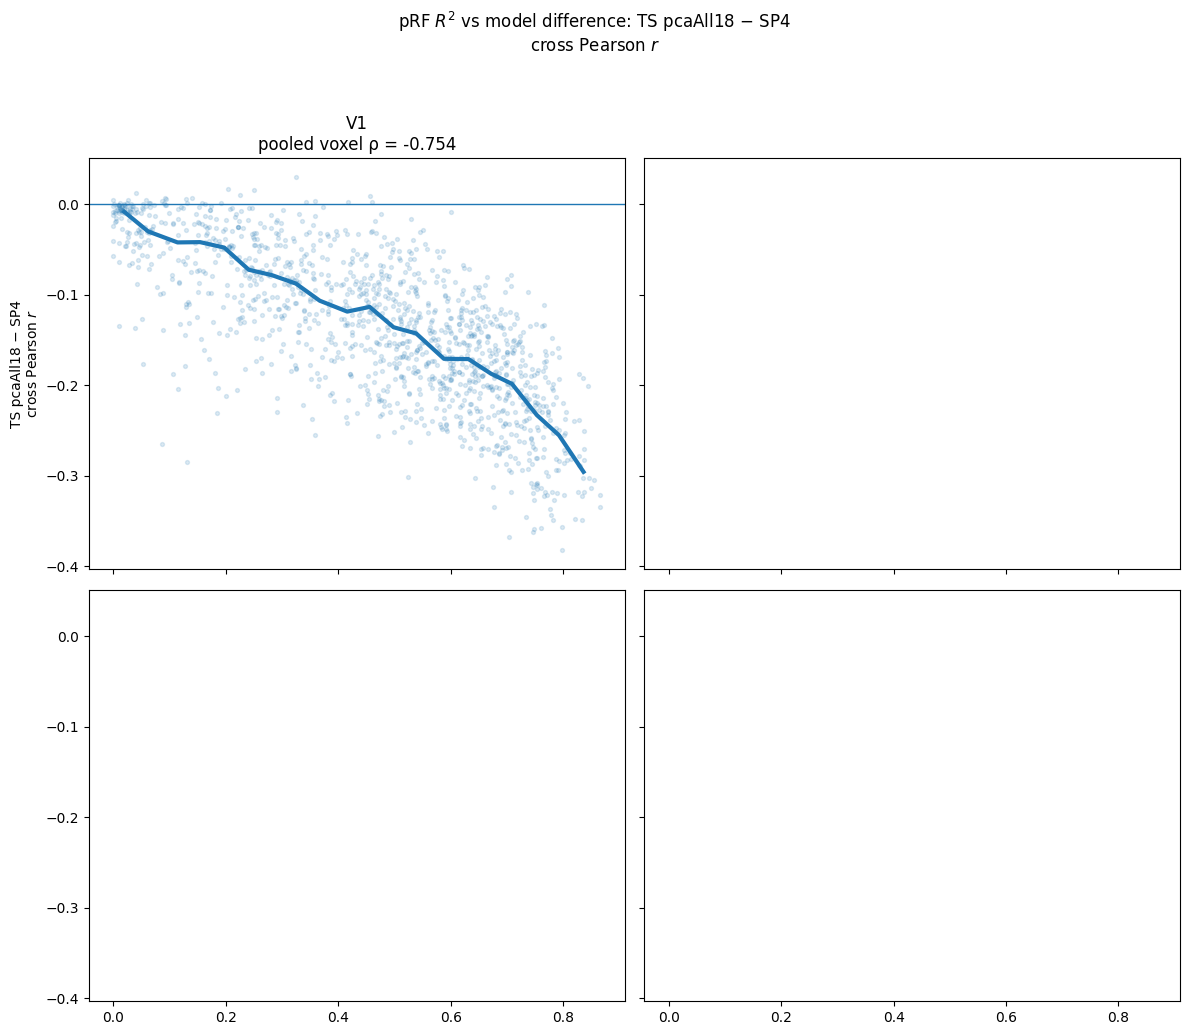

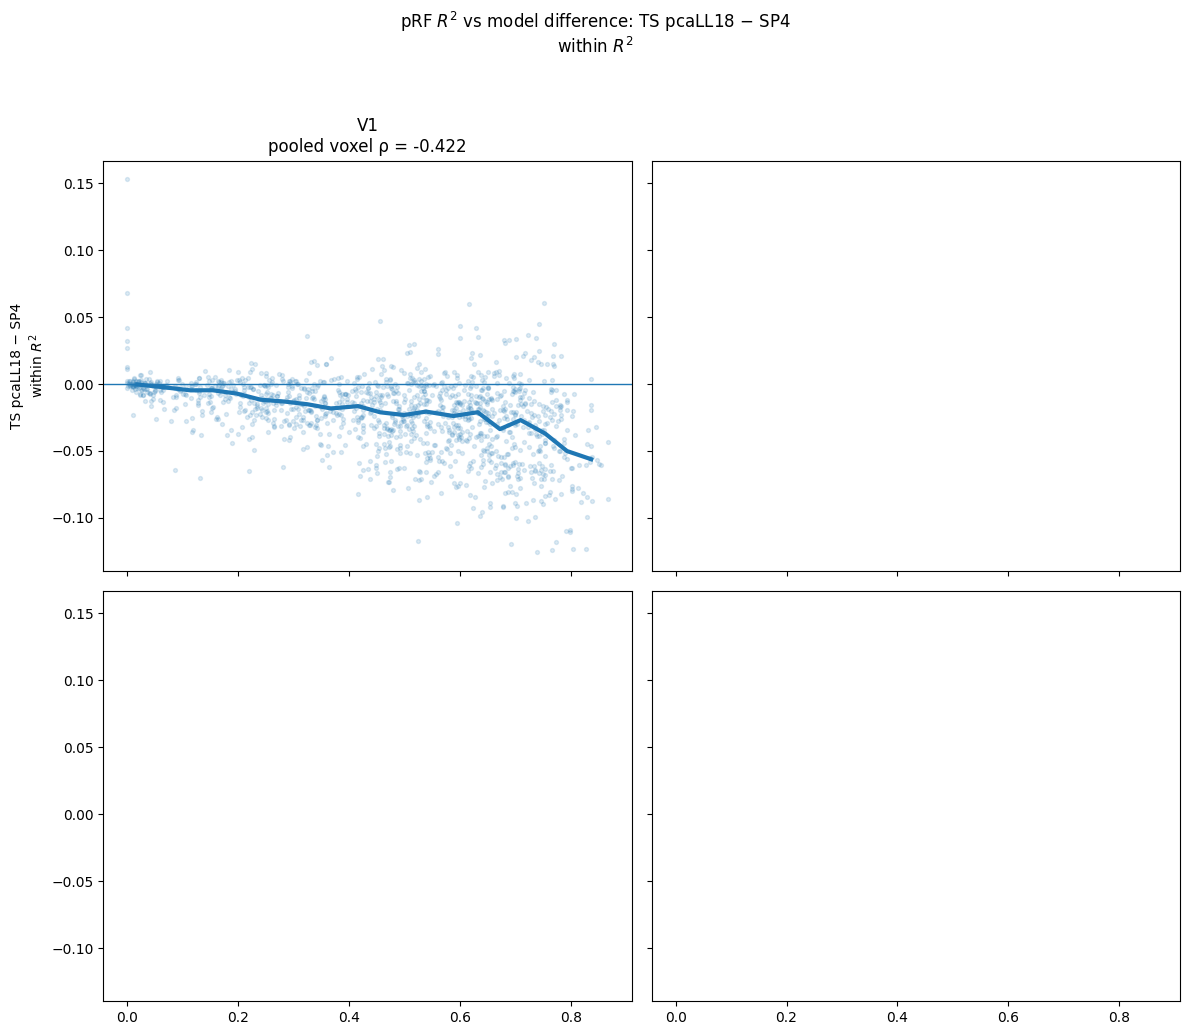

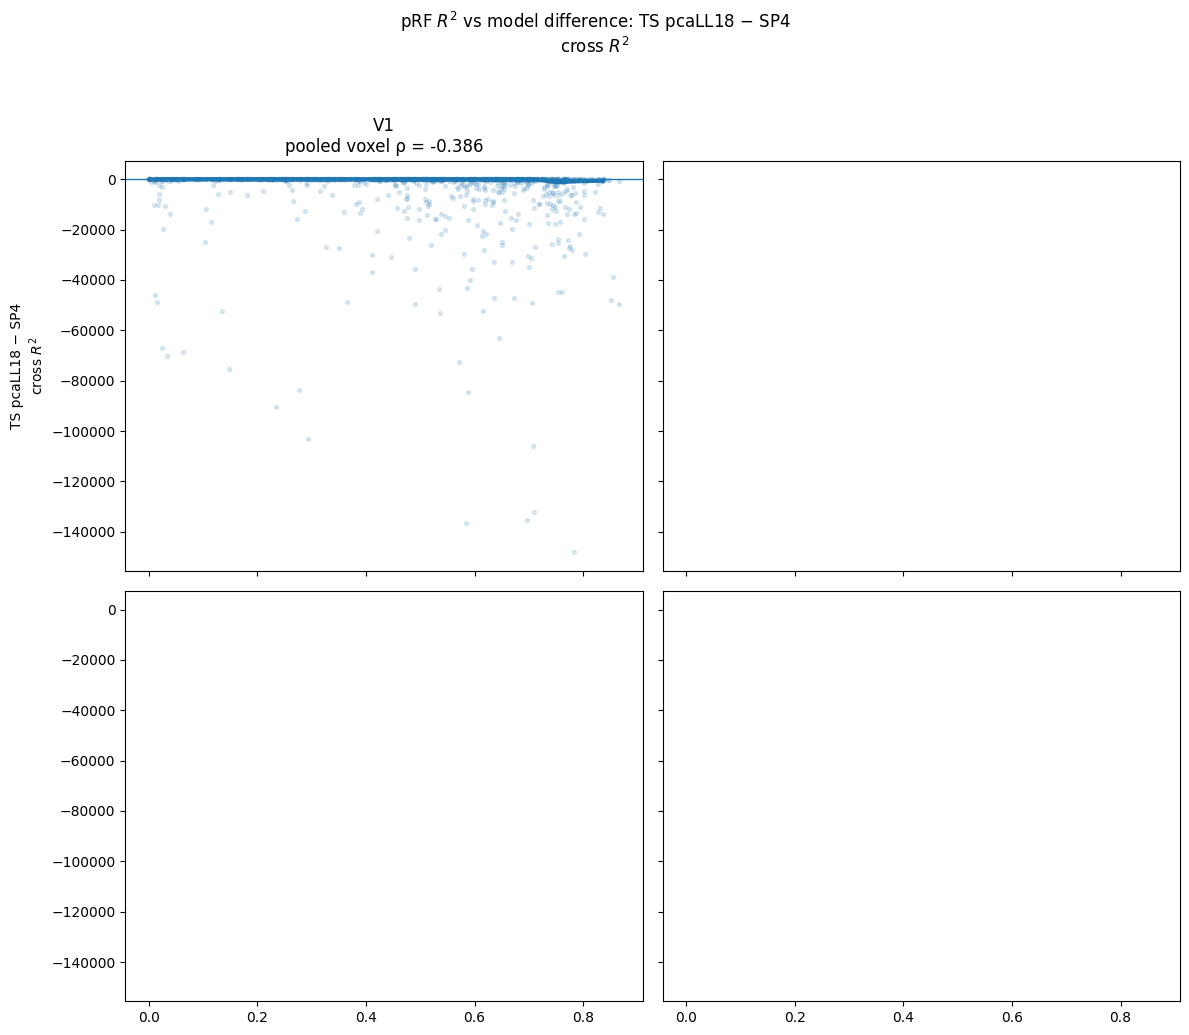

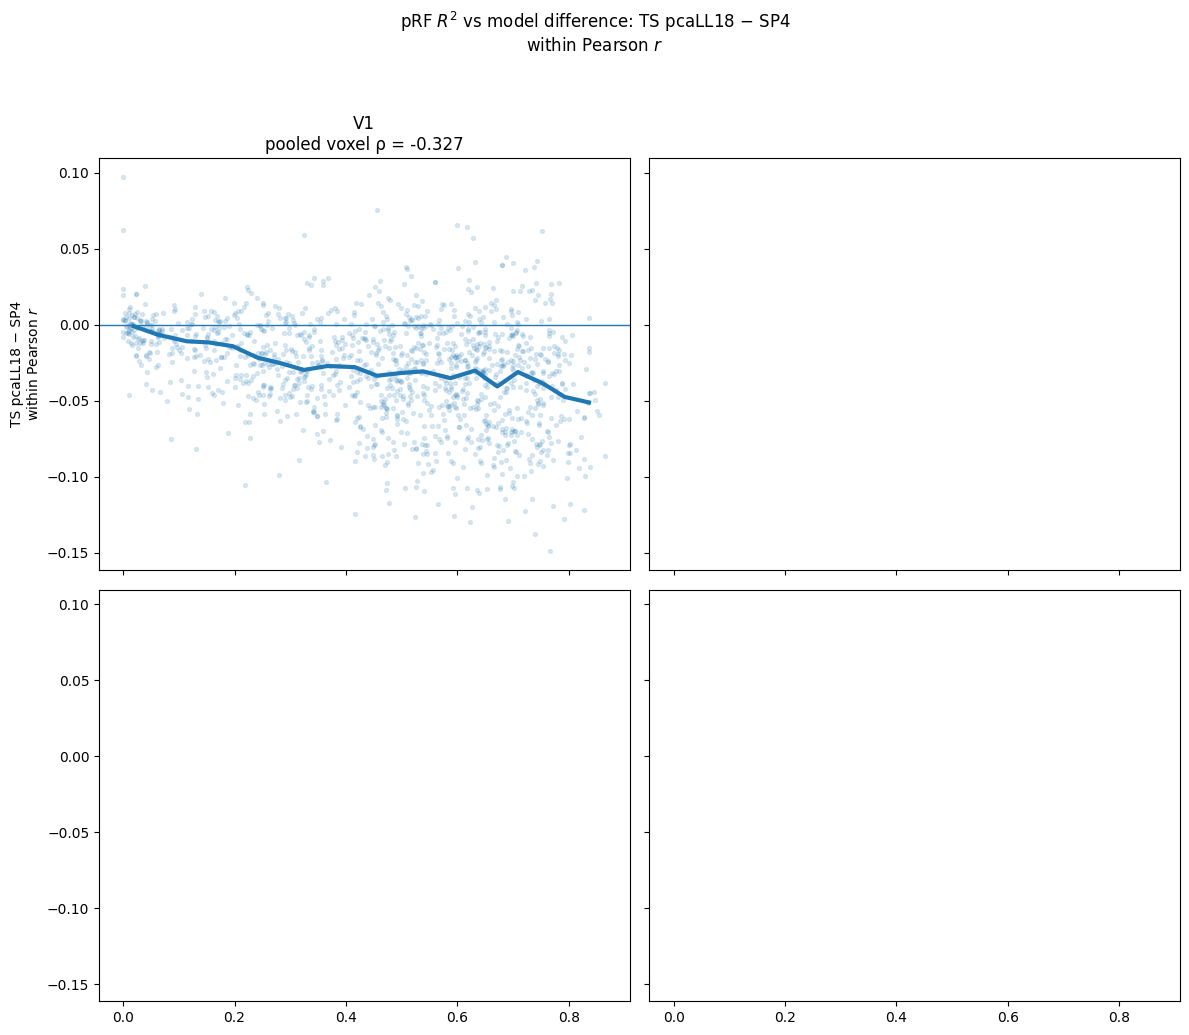

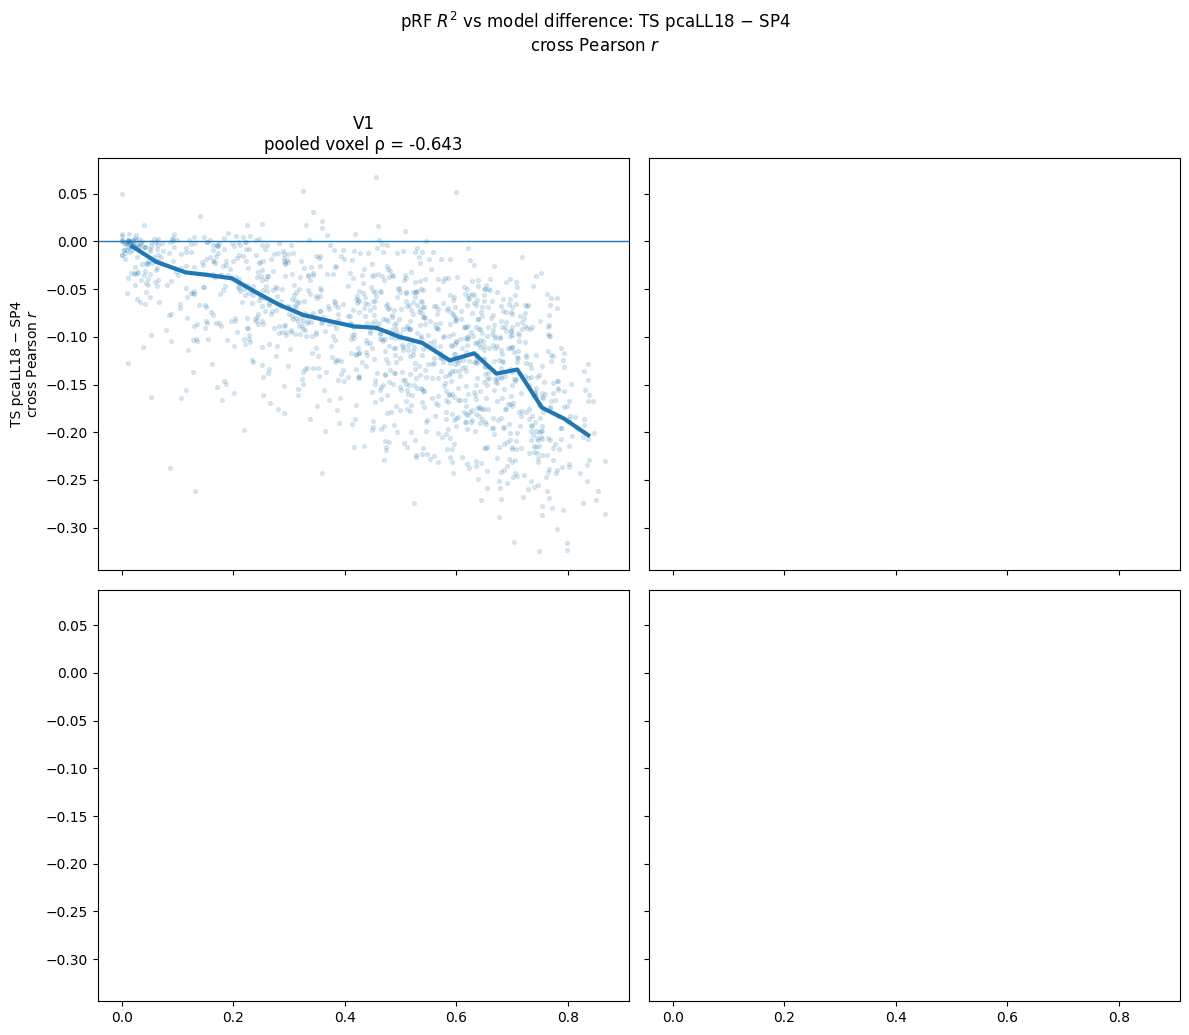

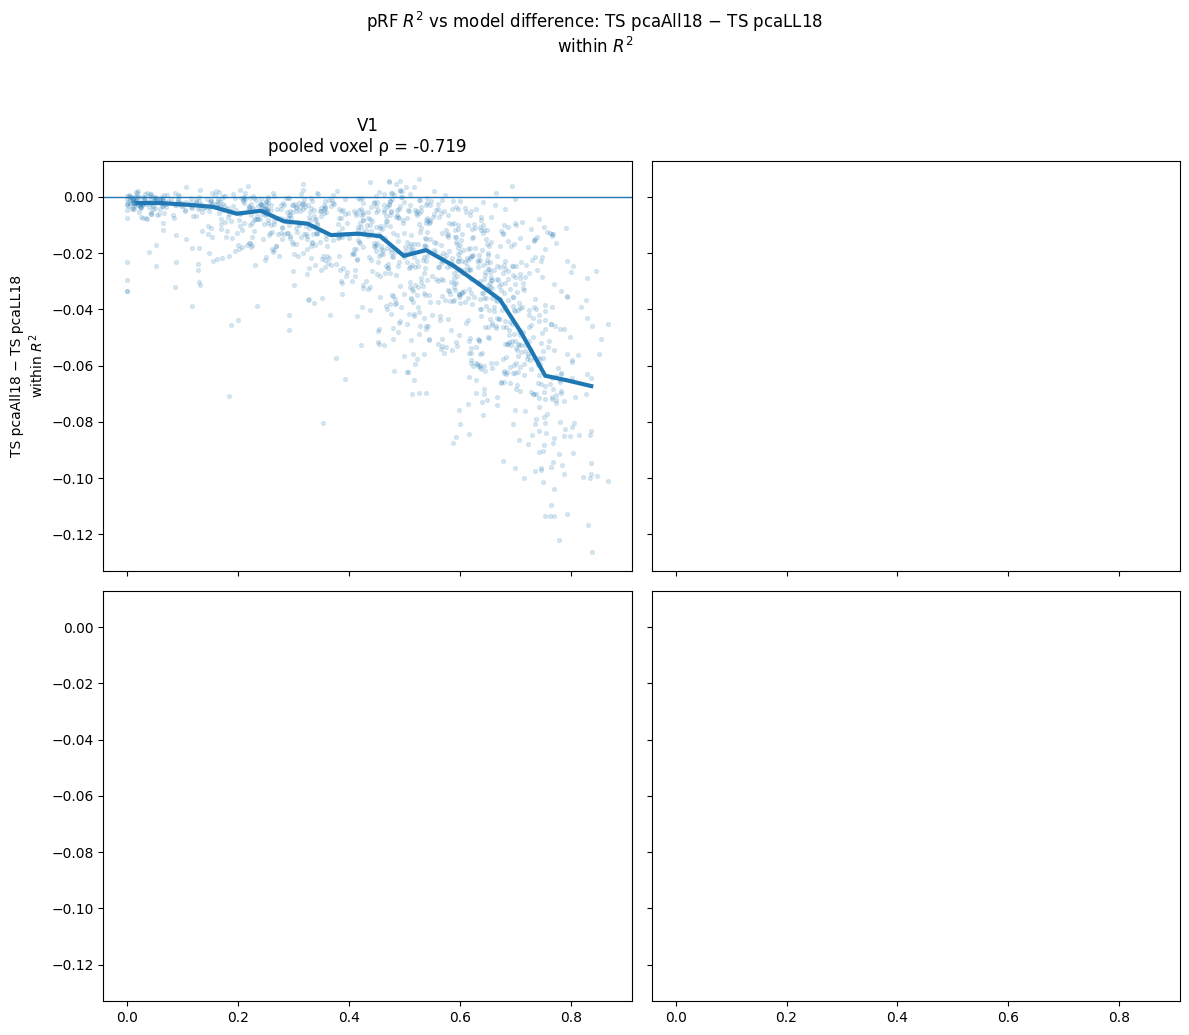

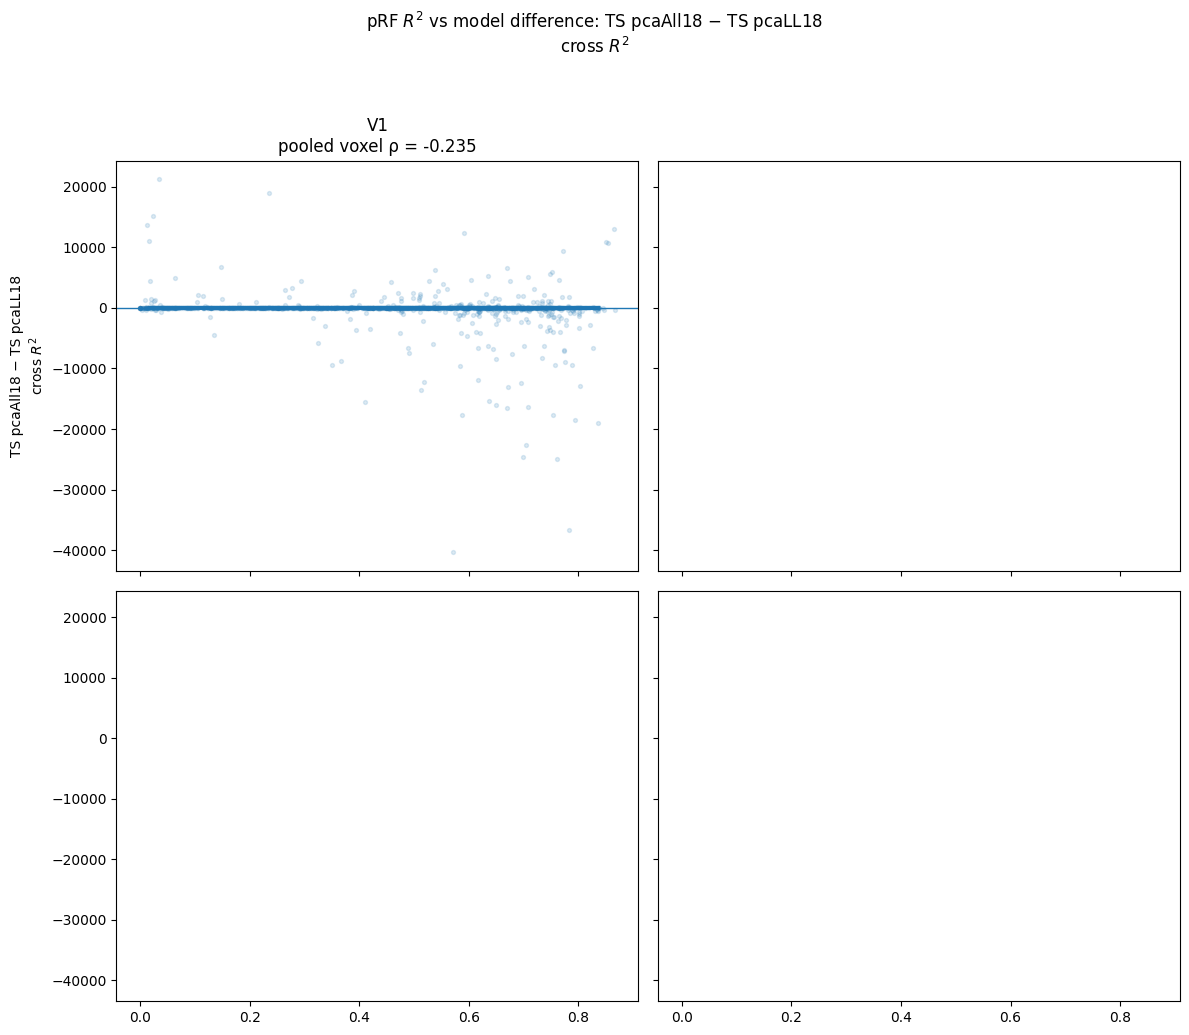

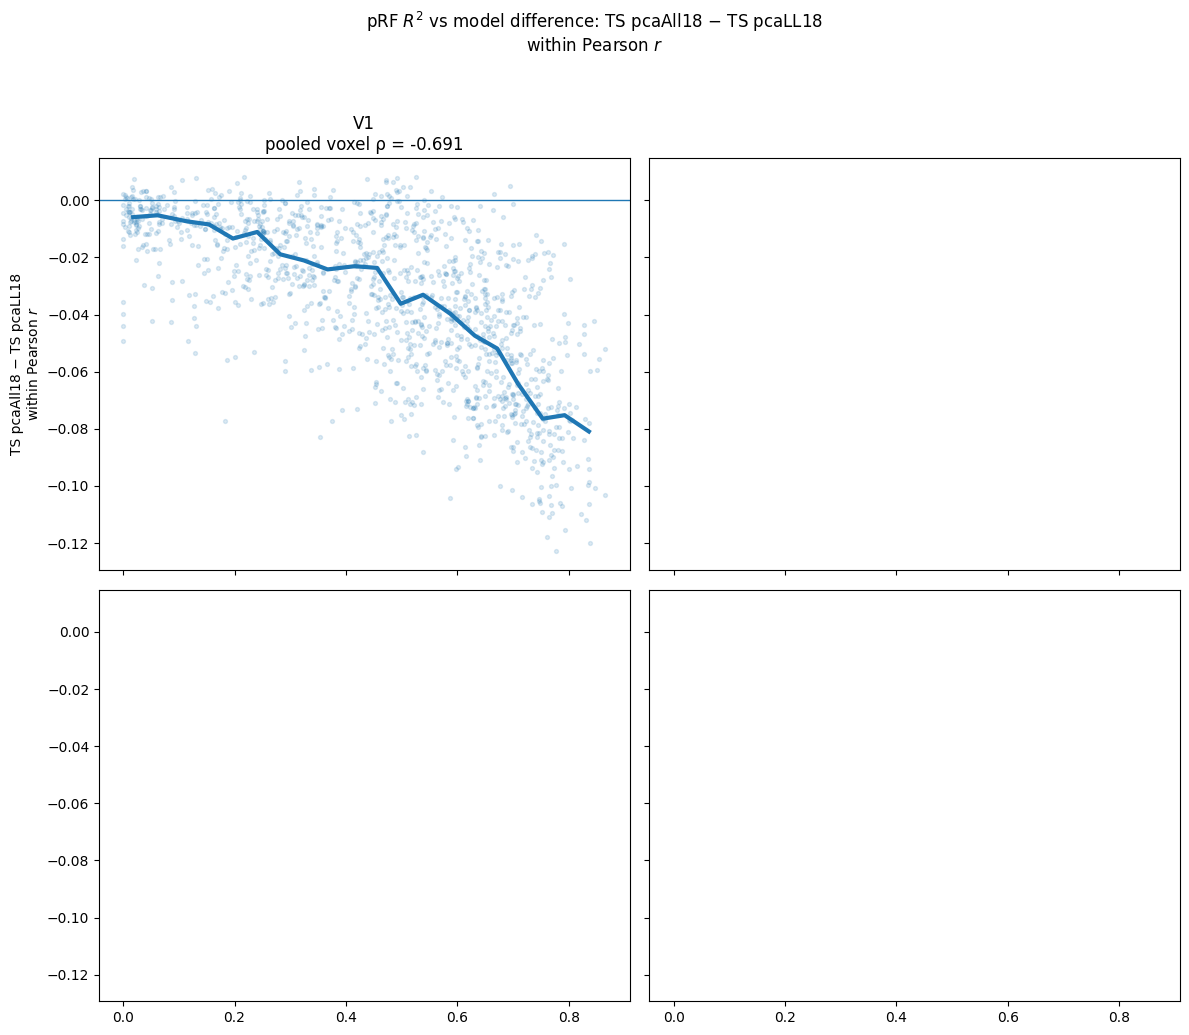

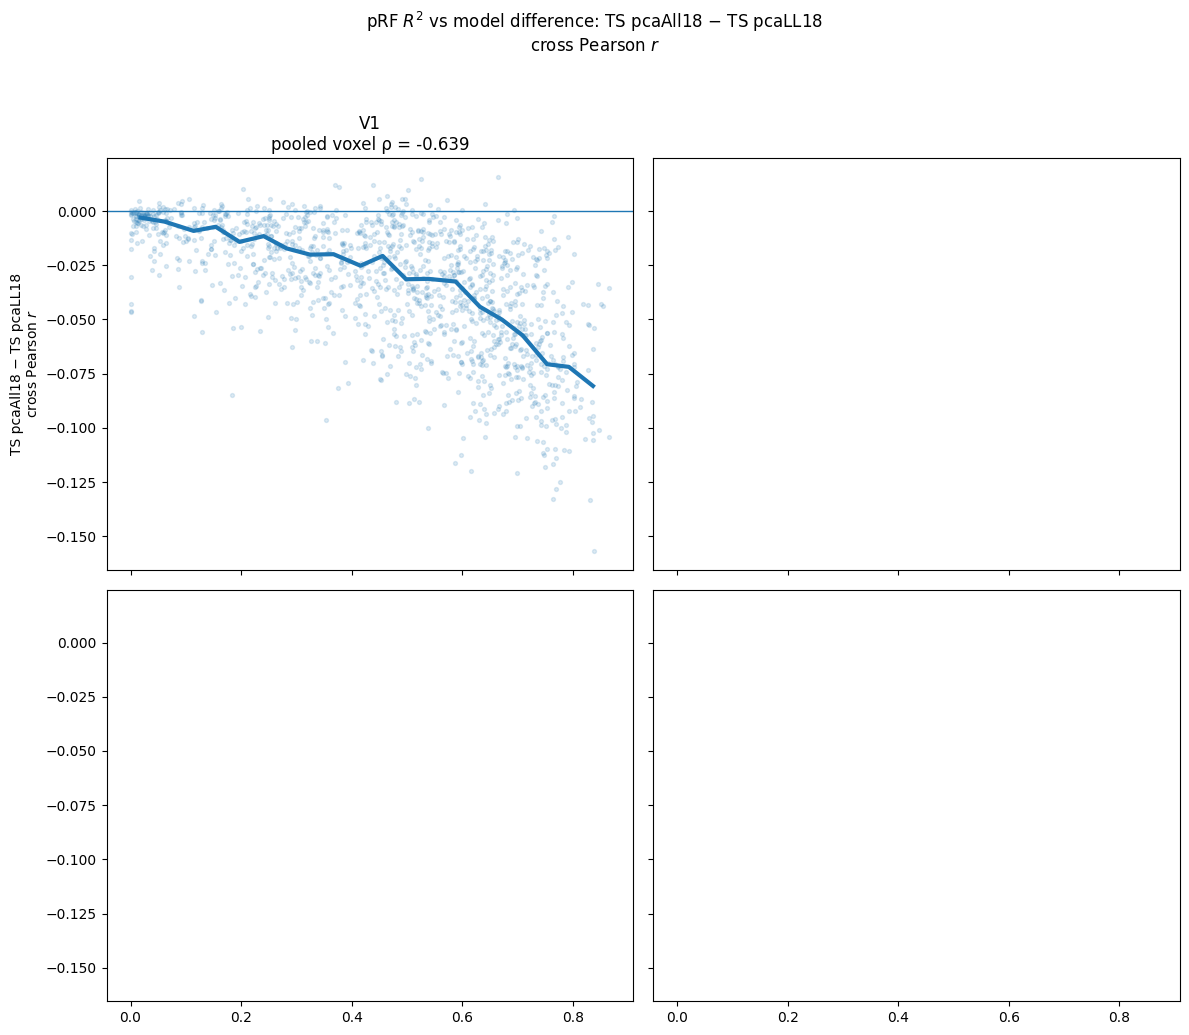

In [ ]:
# =============================================================================
# PAIRWISE COMPARISONS TO GENERATE
# =============================================================================

PAIRWISE_COMPARISONS = [
    ("SP4", "SP6"),
    ("SP4", "TS_pcaHL95"),
    ("TS_pcaHL0", "TS_pcaHL95"),
    ("SP4", "TS_pcaAll18"),
    ("SP4", "TS_pcaLL18"),
    ("TS_pcaLL18", "TS_pcaAll18"),
]

PAIRWISE_RESULTS = {}

for model_a, model_b in PAIRWISE_COMPARISONS:
    if model_a not in ACTIVE_MODELS or model_b not in ACTIVE_MODELS:
        continue

    for metric in METRICS_TO_RUN:
        for scope in SCOPES_TO_RUN:
            try:
                pair_df = plot_prf_vs_model_difference(
                    model_a=model_a,
                    model_b=model_b,
                    metric=metric,
                    scope=scope,
                )

                PAIRWISE_RESULTS[
                    (model_a, model_b, metric, scope)
                ] = pair_df

            except Exception as exc:
                if MISSING_FILE_POLICY == "raise":
                    raise
                print(
                    f"Skipped pair {model_b} - {model_a}, "
                    f"{metric}, {scope}: {exc}"
                )


## 11. Compact numeric summaries

These tables are generated for every model and both metrics automatically.

In [ ]:
# =============================================================================
# GROUP NUMERIC SUMMARIES
# =============================================================================

within_group_summary = (
    within_df
    .groupby(["model", "roi", "metric"])["performance"]
    .agg(["mean", "std", "median"])
    .reset_index()
)

cross_group_summary = (
    cross_df
    .groupby(["model", "roi", "metric"])[
        ["drift_rho", "mean_offdiag_performance"]
    ]
    .agg(["mean", "std", "median"])
)

print("WITHIN-SESSION:")
display(within_group_summary)

print("\nCROSS-SESSION:")
display(cross_group_summary)


WITHIN-SESSION:


,model,roi,metric,mean,std,median
0,SP4,V1,pearson,0.351270,0.024292,0.351703
1,SP4,V1,r2,0.123509,0.017311,0.123202
2,TS_pcaAll18,V1,pearson,0.284705,0.015266,0.286616
3,TS_pcaAll18,V1,r2,0.081282,0.008715,0.082149
4,TS_pcaHL0,V1,pearson,0.416664,0.020837,0.417871
5,TS_pcaHL0,V1,r2,0.174028,0.017584,0.174617
6,TS_pcaLL18,V1,pearson,0.316345,0.018954,0.319127
7,TS_pcaLL18,V1,r2,0.100422,0.012065,0.101842



CROSS-SESSION:


drift_rho               mean_offdiag_performance      \
                             mean std    median                     mean std   
model       roi metric                                                         
SP4         V1  pearson -0.003607 NaN -0.003607                 0.283343 NaN   
                r2      -0.295877 NaN -0.295877                -0.002504 NaN   
TS_pcaAll18 V1  pearson  0.002237 NaN  0.002237                 0.133781 NaN   
                r2      -0.228215 NaN -0.228215                -0.170817 NaN   
TS_pcaHL0   V1  pearson  0.001033 NaN  0.001033                 0.190042 NaN   
                r2      -0.215473 NaN -0.215473                -0.168516 NaN   
TS_pcaLL18  V1  pearson -0.001781 NaN -0.001781                 0.163225 NaN   
                r2      -0.227106 NaN -0.227106                -0.149584 NaN   

                                   
                           median  
model       roi metric             
SP4         V1  pearson  0.283343  
                r2      -0.002504  
TS_pcaAll18 V1  pearson  0.133781  
                r2      -0.170817  
TS_pcaHL0   V1  pearson  0.190042  
                r2      -0.168516  
TS_pcaLL18  V1  pearson  0.163225  
                r2      -0.149584

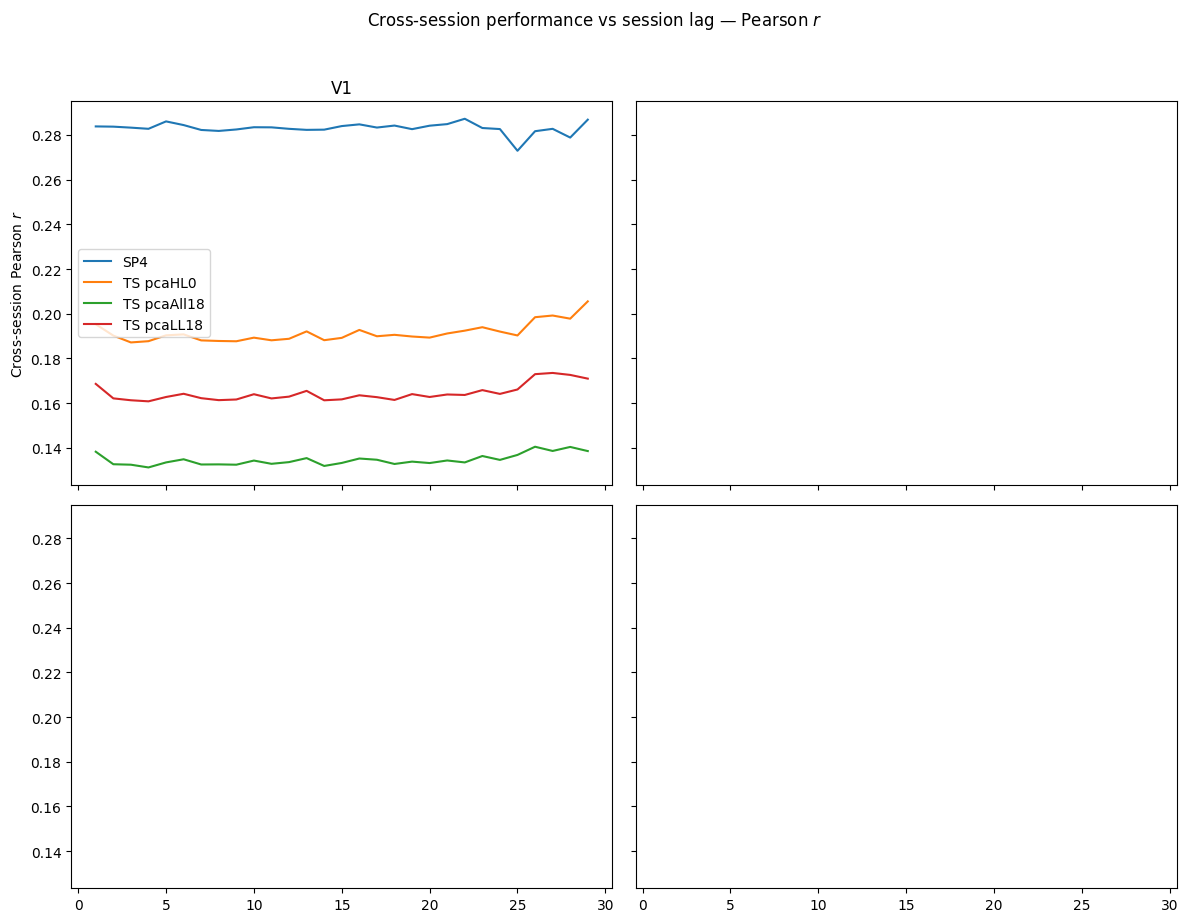

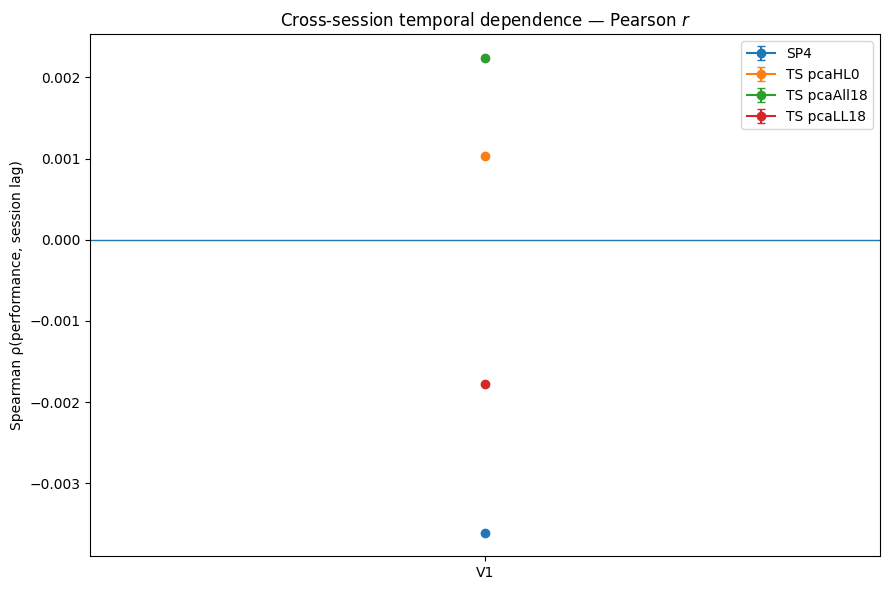

In [ ]:
# =========================================================
# S01 V1 — PEARSON VS SESSION LAG
# =========================================================

MODELS_CHECK = [
    "SP4",
    "TS_pcaHL0",
    "TS_pcaAll18",
    "TS_pcaLL18",
]

plot_cross_lag_curves(
    models=MODELS_CHECK,
    metric="pearson",
)

plot_drift_by_roi(
    models=MODELS_CHECK,
    metric="pearson",
)

In [ ]:
# =========================================================
# NUMERIC PEARSON LAG CURVES — S01 V1
# =========================================================

rows = []

for model in MODELS_CHECK:

    key = (model, 1, "V1")
    if key not in DATA:
        print(f"Skipping {model}: not available")
        continue

    M = get_subject_cross_matrix(
        model=model,
        subject=1,
        roi="V1",
        metric="pearson",
    )

    for lag in range(1, N_SESSIONS):

        mask = lags == lag
        value = np.nanmean(M[mask])

        rows.append({
            "model": model,
            "lag": lag,
            "pearson": value,
        })

pearson_lag_df = pd.DataFrame(rows)

display(
    pearson_lag_df.pivot(
        index="lag",
        columns="model",
        values="pearson",
    )
)

model,SP4,TS_pcaAll18,TS_pcaHL0,TS_pcaLL18
lag,,,,
1,0.283836,0.138210,0.195265,0.168572
2,0.283730,0.132599,0.190189,0.162085
3,0.283288,0.132392,0.187129,0.161242
4,0.282764,0.131165,0.187688,0.160759
5,0.286081,0.133416,0.190309,0.162702
6,0.284438,0.134823,0.190734,0.164144
7,0.282251,0.132484,0.188041,0.162175
8,0.281815,0.132534,0.187782,0.161293
9,0.282470,0.132392,0.187651,0.161585


In [ ]:
from scipy.stats import spearmanr

print("PEARSON TEMPORAL DEPENDENCE — S01 V1\n")

for model in MODELS_CHECK:

    d = pearson_lag_df[
        pearson_lag_df["model"] == model
    ].dropna()

    rho, p = spearmanr(
        d["lag"],
        d["pearson"],
    )

    print(
        f"{model:15s} "
        f"rho = {rho:+.4f}, "
        f"p = {p:.4g}, "
        f"lag1 = {d.iloc[0]['pearson']:.4f}, "
        f"lag29 = {d.iloc[-1]['pearson']:.4f}"
    )

PEARSON TEMPORAL DEPENDENCE — S01 V1

SP4             rho = -0.1103, p = 0.5688, lag1 = 0.2838, lag29 = 0.2869
TS_pcaHL0       rho = +0.6128, p = 0.0004093, lag1 = 0.1953, lag29 = 0.2055
TS_pcaAll18     rho = +0.6020, p = 0.0005508, lag1 = 0.1382, lag29 = 0.1385
TS_pcaLL18      rho = +0.5936, p = 0.0006878, lag1 = 0.1686, lag29 = 0.1709


# prf_r2 across regions

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import nibabel as nib
from pathlib import Path

# ============================================================
# CONFIG
# ============================================================

SUBJECTS = range(1, 9)
ROIS = ["V1", "V2", "V3", "hV4"]

PRF_ROOT = Path("/content/drive/MyDrive/V1_Drift/NSD")

TS_ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits"
)


# ============================================================
# FIND TS FILE
# We only need voxel_index from it
# ============================================================

def get_ts_file(subject, roi):

    folder = (
        TS_ROOT
        / f"S{subject:02d}"
        / "FAST_CROSS_SESSION"
    )

    matches = list(
        folder.glob(
            f"S{subject:02d}_{roi}_"
            f"texture_pyramid_OLS_4ori_4sf_"
            f"pcaHL_{roi}_pca95_"
            f"use_nsd_grid5_pRFs_30x30_cross_session.h5py"
        )
    )

    if len(matches) != 1:
        raise RuntimeError(
            f"S{subject:02d} {roi}: "
            f"found {len(matches)} files"
        )

    return matches[0]


# ============================================================
# LOAD pRF R²
# ============================================================

def load_prf_r2(subject, roi):

    ts_file = get_ts_file(subject, roi)

    # Exact voxels used for this ROI/model
    with h5py.File(ts_file, "r") as f:
        voxel_index = (
            np.asarray(f["voxel_index"])
            .squeeze()
            .astype(int)
        )

    # NSD pRF R²
    r2_path = (
        PRF_ROOT
        / f"subj{subject:02d}"
        / "func1pt8mm"
        / "prf_R2.nii.gz"
    )

    r2_data = nib.load(r2_path).get_fdata()
    r2_flat = r2_data.reshape(-1)

    prf_r2 = r2_flat[voxel_index].astype(float) / 100.0

    prf_r2[prf_r2 < 0] = np.nan
    prf_r2 = np.clip(prf_r2, 0, 1)

    return prf_r2


# ============================================================
# BUILD VOXEL-LEVEL DATAFRAME
# ============================================================

rows = []

for subject in SUBJECTS:

    for roi in ROIS:

        prf_r2 = load_prf_r2(
            subject,
            roi,
        )

        for value in prf_r2:

            rows.append({
                "subject": subject,
                "roi": roi,
                "prf_r2": value,
            })


prf_df = pd.DataFrame(rows)

print("Total voxels:", len(prf_df))

display(
    prf_df.groupby("roi")["prf_r2"].describe()
)

Total voxels: 29574


,count,mean,std,min,25%,50%,75%,max
roi,,,,,,,,
V1,8682.0,0.466525,0.257302,0.0,0.248062,0.513570,0.683309,0.949978
V2,8410.0,0.453215,0.254699,0.0,0.233788,0.500768,0.670431,0.911599
V3,7493.0,0.424133,0.247489,0.0,0.210903,0.452078,0.635543,0.910882
hV4,3677.0,0.375153,0.225726,0.0,0.174417,0.380410,0.558857,0.916380


In [ ]:
# ============================================================
# SUBJECT × ROI SUMMARY
# ============================================================

subject_prf = (
    prf_df
    .groupby(
        ["subject", "roi"],
        as_index=False
    )
    .agg(
        median_prf_r2=("prf_r2", "median"),
        mean_prf_r2=("prf_r2", "mean"),
        n_voxels=("prf_r2", "count"),
    )
)

display(subject_prf)

,subject,roi,median_prf_r2,mean_prf_r2,n_voxels
0,1,V1,0.498395,0.459057,1317
1,1,V2,0.495176,0.455051,1368
2,1,V3,0.552030,0.493879,1166
3,1,hV4,0.372291,0.379616,635
4,2,V1,0.489508,0.444337,1039
5,2,V2,0.370166,0.370600,997
6,2,V3,0.385846,0.374312,1046
7,2,hV4,0.379908,0.354808,455
8,3,V1,0.515426,0.458596,1201
9,3,V2,0.513011,0.454721,1100


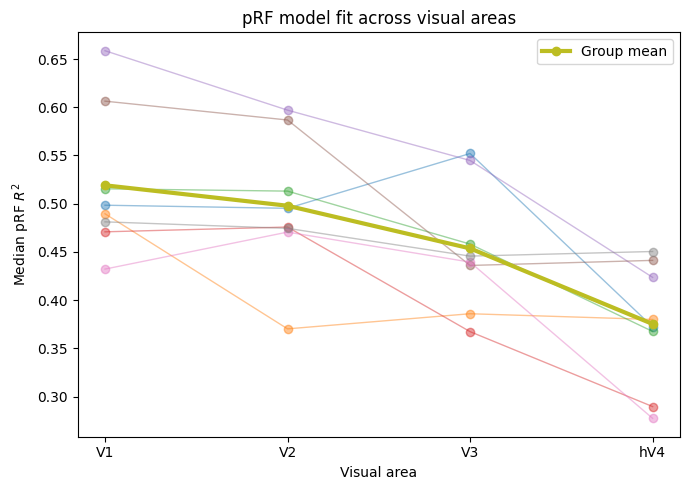

In [ ]:
# ============================================================
# pRF R² ACROSS ROIs
# ============================================================

fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(ROIS))

# Individual subjects
for subject in SUBJECTS:

    d = (
        subject_prf[
            subject_prf["subject"] == subject
        ]
        .set_index("roi")
        .reindex(ROIS)
    )

    ax.plot(
        x,
        d["median_prf_r2"],
        marker="o",
        alpha=0.45,
        linewidth=1,
    )


# Group mean of subject medians
group = (
    subject_prf
    .groupby("roi")["median_prf_r2"]
    .agg(["mean", "std"])
    .reindex(ROIS)
)

ax.plot(
    x,
    group["mean"],
    marker="o",
    linewidth=3,
    label="Group mean",
)

ax.set_xticks(x)
ax.set_xticklabels(ROIS)

ax.set_xlabel("Visual area")
ax.set_ylabel("Median pRF $R^2$")

ax.set_title(
    "pRF model fit across visual areas"
)

ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# GROUP SUMMARY
# ============================================================

summary = (
    subject_prf
    .groupby("roi")["median_prf_r2"]
    .agg(
        mean="mean",
        std="std",
        median="median",
        min="min",
        max="max",
    )
    .reindex(ROIS)
)

display(summary)

,mean,std,median,min,max
roi,,,,,
V1,0.519043,0.075333,0.493952,0.432152,0.658622
V2,0.497849,0.071772,0.485470,0.370166,0.596983
V3,0.453617,0.066171,0.442496,0.367263,0.552030
hV4,0.375218,0.064743,0.376099,0.277360,0.450389


# glm single

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import nibabel as nib
from pathlib import Path

# ============================================================
# CONFIG
# ============================================================

SUBJECTS = range(1, 9)
ROIS = ["V1", "V2", "V3", "hV4"]

NSD_ROOT = Path("/content/drive/MyDrive/V1_Drift/NSD")

TS_ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits"
)


# ============================================================
# FIND TS FILE
# only used to get the exact voxel_index
# ============================================================

def get_ts_file(subject, roi):

    folder = (
        TS_ROOT
        / f"S{subject:02d}"
        / "FAST_CROSS_SESSION"
    )

    matches = list(
        folder.glob(
            f"S{subject:02d}_{roi}_"
            f"texture_pyramid_OLS_4ori_4sf_"
            f"pcaHL_{roi}_pca95_"
            f"use_nsd_grid5_pRFs_30x30_cross_session.h5py"
        )
    )

    if len(matches) != 1:
        raise RuntimeError(
            f"S{subject:02d} {roi}: "
            f"found {len(matches)} files"
        )

    return matches[0]


# ============================================================
# LOAD GLMsingle R²
# ============================================================

def load_glmsingle_r2(subject, roi):

    ts_file = get_ts_file(subject, roi)

    # exact voxels used in the model
    with h5py.File(ts_file, "r") as f:
        voxel_index = (
            np.asarray(f["voxel_index"])
            .squeeze()
            .astype(int)
        )

    r2_path = (
        NSD_ROOT
        / f"subj{subject:02d}"
        / "func1pt8mm"
        / "R2.nii.gz"
    )

    r2_data = nib.load(r2_path).get_fdata()
    r2_flat = r2_data.reshape(-1)

    glm_r2 = r2_flat[voxel_index].astype(float)

    # If stored as percentage, convert to 0-1
    if np.nanmax(glm_r2) > 1:
        glm_r2 = glm_r2 / 100.0

    glm_r2[glm_r2 < 0] = np.nan
    glm_r2 = np.clip(glm_r2, 0, 1)

    return glm_r2


# ============================================================
# BUILD VOXEL-LEVEL DATAFRAME
# ============================================================

rows = []

for subject in SUBJECTS:

    for roi in ROIS:

        glm_r2 = load_glmsingle_r2(
            subject,
            roi,
        )

        for value in glm_r2:

            rows.append({
                "subject": subject,
                "roi": roi,
                "glm_r2": value,
            })


glm_df = pd.DataFrame(rows)

print("Total voxels:", len(glm_df))

display(
    glm_df.groupby("roi")["glm_r2"].describe()
)

Total voxels: 29574


,count,mean,std,min,25%,50%,75%,max
roi,,,,,,,,
V1,9039.0,0.118017,0.098276,0.001235,0.033250,0.096415,0.181602,0.522227
V2,8792.0,0.117012,0.105424,0.001267,0.026530,0.085538,0.182365,0.507309
V3,7761.0,0.117146,0.110643,0.000797,0.023438,0.081946,0.183265,0.546169
hV4,3982.0,0.126132,0.109787,0.001236,0.035145,0.096275,0.189625,0.561055


In [ ]:
subject_glm = (
    glm_df
    .groupby(
        ["subject", "roi"],
        as_index=False
    )
    .agg(
        median_glm_r2=("glm_r2", "median"),
        mean_glm_r2=("glm_r2", "mean"),
        n_voxels=("glm_r2", "count"),
    )
)

display(subject_glm)

,subject,roi,median_glm_r2,mean_glm_r2,n_voxels
0,1,V1,0.131584,0.144859,1350
1,1,V2,0.084772,0.125526,1433
2,1,V3,0.122638,0.152615,1187
3,1,hV4,0.105708,0.137019,687
4,2,V1,0.058462,0.096404,1102
5,2,V2,0.041692,0.066464,1075
6,2,V3,0.051133,0.087865,1097
7,2,hV4,0.121418,0.132575,483
8,3,V1,0.092259,0.106772,1254
9,3,V2,0.097877,0.118845,1141


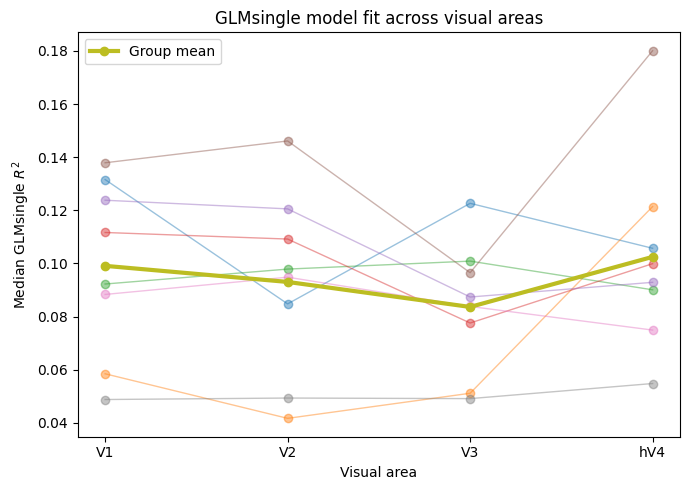

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(ROIS))

# individual subjects
for subject in SUBJECTS:

    d = (
        subject_glm[
            subject_glm["subject"] == subject
        ]
        .set_index("roi")
        .reindex(ROIS)
    )

    ax.plot(
        x,
        d["median_glm_r2"],
        marker="o",
        alpha=0.45,
        linewidth=1,
    )


# group mean
group = (
    subject_glm
    .groupby("roi")["median_glm_r2"]
    .agg(["mean", "std"])
    .reindex(ROIS)
)

ax.plot(
    x,
    group["mean"],
    marker="o",
    linewidth=3,
    label="Group mean",
)

ax.set_xticks(x)
ax.set_xticklabels(ROIS)

ax.set_xlabel("Visual area")
ax.set_ylabel("Median GLMsingle $R^2$")

ax.set_title(
    "GLMsingle model fit across visual areas"
)

ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
summary = (
    subject_glm
    .groupby("roi")["median_glm_r2"]
    .agg(
        mean="mean",
        std="std",
        median="median",
        min="min",
        max="max",
    )
    .reindex(ROIS)
)

display(summary)

,mean,std,median,min,max
roi,,,,,
V1,0.099096,0.033112,0.101957,0.048777,0.137900
V2,0.093044,0.034798,0.096356,0.041692,0.146115
V3,0.083629,0.024736,0.085586,0.049117,0.122638
hV4,0.102478,0.037181,0.096411,0.054799,0.180084
